# Sliding-Window Attention: Memory, Speed, and Hardware Tradeoffs

**Project overview**

My project will extend RAPID-LLM to model sliding-window attention and study how it changes the memory and processing work required by a language model.

The project will investigate these questions:

1. **Memory:** How much KV-cache memory can sliding-window attention save compared with full attention?
2. **Response speed:** When do those savings translate into faster token generation?
3. **Hardware tradeoffs:** How do conversation length, window size, the mix of local/global layers, and GPU memory capacity and bandwidth affect the benefit?
4. **Validation:** How closely do our calculations and simulator predictions match suitable published measurements?

Answer quality is an important tradeoff. We will discuss the chosen architecture's published quality evaluations alongside our hardware results. RAPID-LLM models execution costs; it does not evaluate the quality of generated answers.

## Our starting point: one layer's KV-cache memory

The first exercise focuses on a smaller question: **How much KV-cache memory does sliding-window attention save compared with full attention for one layer, and how do two choices of inputs change that saving?**

This first experiment is a hand calculation implemented in Python, using illustrative values. It establishes the memory calculation we will build on. We will connect the real simulator in a later step, then expand to mixed local/global layers and performance experiments.


## 1. What are we counting?

A token is a piece of text. An attention layer stores two sets of numerical information for earlier token positions: **keys (K)** and **values (V)**. Together, these are the **KV cache**.

We compare the resident cache for **one layer**:

- Full attention retains information for all available token positions.
- Sliding-window attention retains information for at most `window_tokens` positions, assuming older entries are actually removed.

For this exercise, context and window sizes count visible positions including the current position. The real simulator’s convention must be checked later.

Model weights, temporary working memory, other layers, and execution time are outside this first calculation. There is no answer-quality measurement here.

### Enter two cases to compare

Edit `scenario_a` and `scenario_b` in the input cell below, then **Run All** to refresh the tables. The display code stays in separate, collapsible cells.

The default comparison changes only the local window: **1,024 tokens in A** and **2,048 tokens in B**. You can compare two values of any setting by changing that setting between A and B while keeping the others equal. All inputs must be positive integers.


In [140]:
scenario_a = {
    "batch_size": 1,             # Conversations processed together
    "context_tokens": 32_768,    # Available token positions
    "window_tokens": 1_024,      # Maximum positions retained locally
    "kv_heads": 8,               # Stored key/value heads
    "head_dimension": 128,       # Numbers per head for each of K and V
    "bytes_per_number": 2,       # Bytes per stored number
}

scenario_b = {
    "batch_size": 1,
    "context_tokens": 32_768,
    "window_tokens": 2_048,      # Compare a larger window by default
    "kv_heads": 8,
    "head_dimension": 128,
    "bytes_per_number": 2,
}


In [141]:
# Generate figure
from html import escape
from IPython.display import HTML, display

UCLA_BLUE = "#2774AE"
UCLA_GOLD = "#FFD100"


def show_table(title, headers, rows, note=""):
    """Display a compact table; values are supplied by the calculation."""
    header_cells = ""
    for header in headers:
        # Match Scenario B's headers to its gold bars; keep gold text dark.
        is_case_b = str(header).startswith(("Scenario B", "B "))
        background = UCLA_GOLD if is_case_b else UCLA_BLUE
        foreground = "#243746" if is_case_b else "white"
        header_cells += (
            f'<th scope="col" style="padding:10px 14px; text-align:left; '
            f'background:{background}; color:{foreground};">{escape(str(header))}</th>'
        )
    body_rows = "".join(
        '<tr>' + "".join(
            f'<td style="padding:10px 14px; text-align:left; '
            f'border-bottom:1px solid #dce5ed;">{escape(str(value))}</td>'
            for value in row
        ) + '</tr>'
        for row in rows
    )
    display(HTML(
        '<div style="max-width:850px; overflow-x:auto; '
        'font-family:system-ui,sans-serif; color:#243746;">'
        '<table style="width:100%; border-collapse:collapse; '
        'background:white; font-size:14px;">'
        f'<caption style="caption-side:top; text-align:left; padding:12px 0; '
        f'font-weight:600; font-size:17px; color:{UCLA_BLUE};">'
        f'{escape(title)}</caption>'
        f'<thead><tr>{header_cells}</tr></thead><tbody>{body_rows}</tbody></table>'
        f'<p style="font-size:13px; color:#FFFFFF; margin:10px 0;">'
        f'{escape(note)}</p></div>'
    ))


scenarios = {"A": scenario_a, "B": scenario_b}
input_fields = [
    ("batch_size", "Batch size", "Conversations processed together"),
    ("context_tokens", "Context (tokens)", "Available token positions"),
    ("window_tokens", "Local window (tokens)", "Maximum positions retained locally"),
    ("kv_heads", "KV heads", "Stored key/value heads"),
    ("head_dimension", "Head dimension", "Numbers per head for each of K and V"),
    ("bytes_per_number", "Bytes per number", "Precision assumed for the cache"),
]
for name, scenario in scenarios.items():
    for key, label, _ in input_fields:
        if type(scenario[key]) is not int or scenario[key] <= 0:
            raise ValueError(f"Scenario {name}: {label} must be a positive integer.")

show_table(
    "Compare experiment inputs · one attention layer",
    ["Parameter", "Scenario A", "Scenario B", "Meaning"],
    [
        (label, f"{scenario_a[key]:,}", f"{scenario_b[key]:,}", meaning)
        for key, label, meaning in input_fields
    ],
    note="Illustrative assumptions; context and window include the current position.",
)


Parameter,Scenario A,Scenario B,Meaning
Batch size,1,1,Conversations processed together
Context (tokens),"32,768","32,768",Available token positions
Local window (tokens),"1,024","2,048",Maximum positions retained locally
KV heads,8,8,Stored key/value heads
Head dimension,128,128,Numbers per head for each of K and V
Bytes per number,2,2,Precision assumed for the cache


## 2. Calculate the cache size

The calculation is:

**Cache bytes = 2 × conversations × retained token positions × KV heads × head dimension × bytes per number**

The first **2** is for storing both keys and values. `bytes_per_number` separately describes the storage size of each number.

We display memory in **MiB**, where 1 MiB = 1,048,576 bytes. The number of KV heads describes cache storage; it can differ from the number of query heads used to compute attention.


In [142]:
# Calculate and display both scenarios.
def kv_cache_mib(retained_tokens, scenario):
    """Resident KV-cache size of one illustrative, unsharded layer."""
    cache_bytes = (
        2 * scenario["batch_size"] * retained_tokens
        * scenario["kv_heads"] * scenario["head_dimension"]
        * scenario["bytes_per_number"]
    )
    return cache_bytes / (1024 ** 2)


def cache_summary(scenario):
    retained = min(scenario["context_tokens"], scenario["window_tokens"])
    full = kv_cache_mib(scenario["context_tokens"], scenario)
    local = kv_cache_mib(retained, scenario)
    return {
        "retained_tokens": retained,
        "full_mib": full,
        "local_mib": local,
        "saved_mib": full - local,
        "reduction": full / local,
        "saved_percent": 100 * (1 - local / full),
    }


results = {name: cache_summary(scenario) for name, scenario in scenarios.items()}
a, b = results["A"], results["B"]
show_table(
    "KV-cache memory comparison · one layer",
    ["Metric", "Scenario A", "Scenario B"],
    [
        ("Local cached positions", f"{a['retained_tokens']:,}", f"{b['retained_tokens']:,}"),
        ("Full-attention cache", f"{a['full_mib']:,.2f} MiB", f"{b['full_mib']:,.2f} MiB"),
        ("Sliding-window cache", f"{a['local_mib']:,.2f} MiB", f"{b['local_mib']:,.2f} MiB"),
        ("Memory saved vs. full", f"{a['saved_mib']:,.2f} MiB", f"{b['saved_mib']:,.2f} MiB"),
        ("Full / window cache", f"{a['reduction']:,.1f}×", f"{b['reduction']:,.1f}×"),
        ("Memory saved (%)", f"{a['saved_percent']:,.3f}%", f"{b['saved_percent']:,.3f}%"),
    ],
    note="Each scenario uses its own full-attention baseline. Assumes old entries are evicted.",
)

local_difference = b["local_mib"] - a["local_mib"]
if local_difference == 0:
    comparison = "Scenarios A and B use the same sliding-window cache memory."
else:
    direction = "more" if local_difference > 0 else "less"
    comparison = (
        f"Scenario B uses {abs(local_difference):,.2f} MiB {direction} "
        "sliding-window cache memory than Scenario A."
    )
display(HTML(
    f'<p style="font-family:system-ui,sans-serif; color:#FFFFFF;">'
    f'{escape(comparison)}</p>'
))


Metric,Scenario A,Scenario B
Local cached positions,"1,024","2,048"
Full-attention cache,128.00 MiB,128.00 MiB
Sliding-window cache,4.00 MiB,8.00 MiB
Memory saved vs. full,124.00 MiB,120.00 MiB
Full / window cache,32.0×,16.0×
Memory saved (%),96.875%,93.750%


## 3. Interpret the result

With the default inputs, both cases have a **128 MiB full-attention cache**. Scenario A's 1,024-token window uses **4 MiB** (32× reduction), while Scenario B's 2,048-token window uses **8 MiB** (16× reduction). Doubling the window doubles the local cache in this example.

These numbers describe the defaults only. The comparison above updates when you edit the inputs and rerun all cells. If you change several settings at once, the memory difference reflects their combined effects.

The reduction factor compares each scenario's full-attention cache with its own sliding-window cache. It does not predict the same improvement in response speed or total GPU memory: weights, other layers, and temporary memory still contribute. A mixed model also has global layers that retain the full context.

The memory saving assumes eviction of old local-cache entries. A windowed attention mask alone does not guarantee a smaller allocation.


In [143]:
# Compare how both scenarios behave as the available context grows.
context_rows = []
for tokens in [512, 1_024, 4_096, 32_768]:
    row = [f"{tokens:,}"]
    for scenario in scenarios.values():
        full = kv_cache_mib(tokens, scenario)
        local = kv_cache_mib(min(tokens, scenario["window_tokens"]), scenario)
        row.extend([f"{full:,.2f}", f"{local:,.2f}"])
    context_rows.append(row)

show_table(
    "Context-length sweep · both scenarios",
    ["Context (tokens)", "A full (MiB)", "A window (MiB)", "B full (MiB)", "B window (MiB)"],
    context_rows,
    note=(
        f"Window limits: A = {scenario_a['window_tokens']:,}; "
        f"B = {scenario_b['window_tokens']:,} tokens. "
        "This sweep replaces each scenario's context length and keeps its other inputs fixed."
    ),
)


Context (tokens),A full (MiB),A window (MiB),B full (MiB),B window (MiB)
512,2.00,2.00,2.00,2.00
"1,024",4.00,4.00,4.00,4.00
"4,096",16.00,4.00,16.00,8.00
"32,768",128.00,4.00,128.00,8.00


## 4. Running comparisons


In [144]:
# Model assumptions held fixed unless an experiment overrides them.
experiment_baseline = {
    "batch_size": 1,
    "context_tokens": 32_768,
    "window_tokens": 1_024,
    "kv_heads": 8,
    "head_dimension": 128,
    "bytes_per_number": 2,
}

# Each case applies these overrides to a fresh copy of the baseline.
experiment_cases = [
    {
        "name": "More conversations",
        "changed": "batch_size",
        "a": {"batch_size": 1},
        "b": {"batch_size": 2},
    },
    {
        "name": "Larger window",
        "changed": "window_tokens",
        "a": {"window_tokens": 1_024},
        "b": {"window_tokens": 2_048},
    },
    {
        "name": "Short context",
        "changed": "window_tokens",
        "a": {"context_tokens": 512, "window_tokens": 1_024},
        "b": {"context_tokens": 512, "window_tokens": 2_048},
    },
]


In [145]:
# Draw each comparison with changed inputs separated from memory outputs.
from io import BytesIO
from IPython.display import Image
from matplotlib.figure import Figure
from matplotlib.ticker import MaxNLocator

experiment_results = []


def plot_experiment(index):
    case = experiment_cases[index]
    cases = [{**experiment_baseline, **case[side]} for side in ("a", "b")]
    changed = case["changed"]
    for scenario in cases:
        for key, label, _ in input_fields:
            if type(scenario[key]) is not int or scenario[key] <= 0:
                raise ValueError(f"{case['name']}: {label} must be a positive integer.")
    if any(cases[0][key] != cases[1][key] for key in experiment_baseline if key != changed):
        raise ValueError("Compare one input at a time; keep other settings equal.")

    values = [cache_summary(scenario) for scenario in cases]
    experiment_results.append({"name": case["name"], "inputs": cases, "results": values})
    input_name = dict((key, label) for key, label, _ in input_fields)[changed]
    fixed = " · ".join(
        f"{label}: {cases[0][key]:,}"
        for key, label, _ in input_fields if key != changed
    )
    display(HTML(
        '<div style="max-width:1000px; font-family:system-ui,sans-serif; '
        'color:#FFFFFF; margin:10px 0;">'
        f'<p style="margin:0 0 6px; color:{UCLA_BLUE}; font-size:16px;">'
        f'<strong>Input changed:</strong> {escape(input_name)} '
        f'{cases[0][changed]:,} → {cases[1][changed]:,}</p>'
        f'<p style="margin:0; font-size:13px;"><strong>Held fixed:</strong> '
        f'{escape(fixed)}</p></div>'
    ))

    # Separate, zero-based scales keep both large and small cache sizes readable.
    fig = Figure(figsize=(10, 3.2), facecolor="white", layout="constrained")
    axes = fig.subplots(1, 2)
    labels = [f"{name} · {scenario[changed]:,}" for name, scenario in zip(("A", "B"), cases)]
    for ax, metric, title in zip(
        axes, ["full_mib", "local_mib"],
        ["Full-attention cache", "Sliding-window cache"],
    ):
        memory = [value[metric] for value in values]
        bars = ax.barh([0, 1], memory, color=[UCLA_BLUE, UCLA_GOLD], height=0.48)
        ax.set_yticks([0, 1], labels)
        ax.set_ylabel(input_name, color="#243746", labelpad=8)
        ax.set_ylim(1.65, -0.65)
        ax.set_xlim(0, max(memory) * 1.35)
        ax.set_xlabel("KV-cache memory per layer (MiB)", color="#243746")
        ax.set_title(title, loc="left", color=UCLA_BLUE, fontsize=12, pad=14)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#e6ebef", linewidth=0.8)
        ax.tick_params(axis="both", length=0, colors="#526575", labelsize=10)
        for spine in ax.spines.values():
            spine.set_visible(False)
        for bar, amount in zip(bars, memory):
            ax.text(
                amount + max(memory) * 0.025,
                bar.get_y() + bar.get_height() / 2,
                f"{amount:,.2f} MiB", va="center", fontsize=10, color="#243746",
            )
    fig.supxlabel("Outputs: cache memory · Separate memory scale in each panel", fontsize=10, color="#526575")
    image_buffer = BytesIO()
    fig.savefig(image_buffer, format="png", dpi=160, facecolor="white")
    display(Image(data=image_buffer.getvalue(), width=1000))

    a, b = values
    if changed == "batch_size":
        explanation = (
            f"Changing batch size from {cases[0][changed]:,} to {cases[1][changed]:,} "
            f"changes full-attention memory from {a['full_mib']:g} to {b['full_mib']:g} MiB "
            f"and local memory from {a['local_mib']:g} to {b['local_mib']:g} MiB. "
            f"Both caches scale with batch size, so the reduction stays {a['reduction']:g}×."
        )
    elif all(scenario["context_tokens"] <= scenario["window_tokens"] for scenario in cases):
        explanation = (
            f"The {cases[0]['context_tokens']:,}-token context fits inside both windows, "
            f"so both retain every available position. Each uses {a['local_mib']:g} MiB "
            "for both full and local attention, giving no cache-memory saving."
        )
    else:
        explanation = (
            f"Changing the window from {cases[0][changed]:,} to {cases[1][changed]:,} tokens "
            f"changes local memory from {a['local_mib']:g} to {b['local_mib']:g} MiB; "
            f"full-attention memory stays {a['full_mib']:g} MiB. "
            f"The cache reduction changes from {a['reduction']:g}× to {b['reduction']:g}×."
        )
    display(HTML(
        '<p style="max-width:1000px; font-family:system-ui,sans-serif; '
        f'color:#FFFFFF; line-height:1.5;">{escape(explanation)}</p>'
    ))


### 4.1. Experiment: More conversations


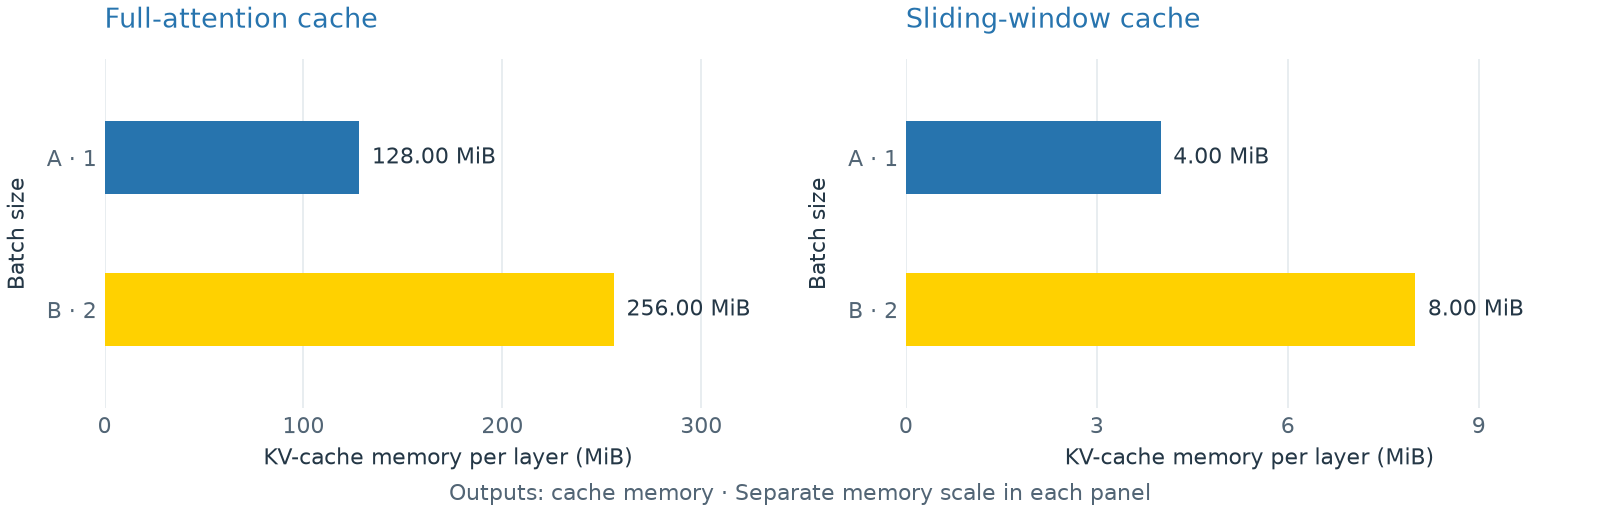

In [146]:
plot_experiment(0)


### 4.2. Experiment: Larger window


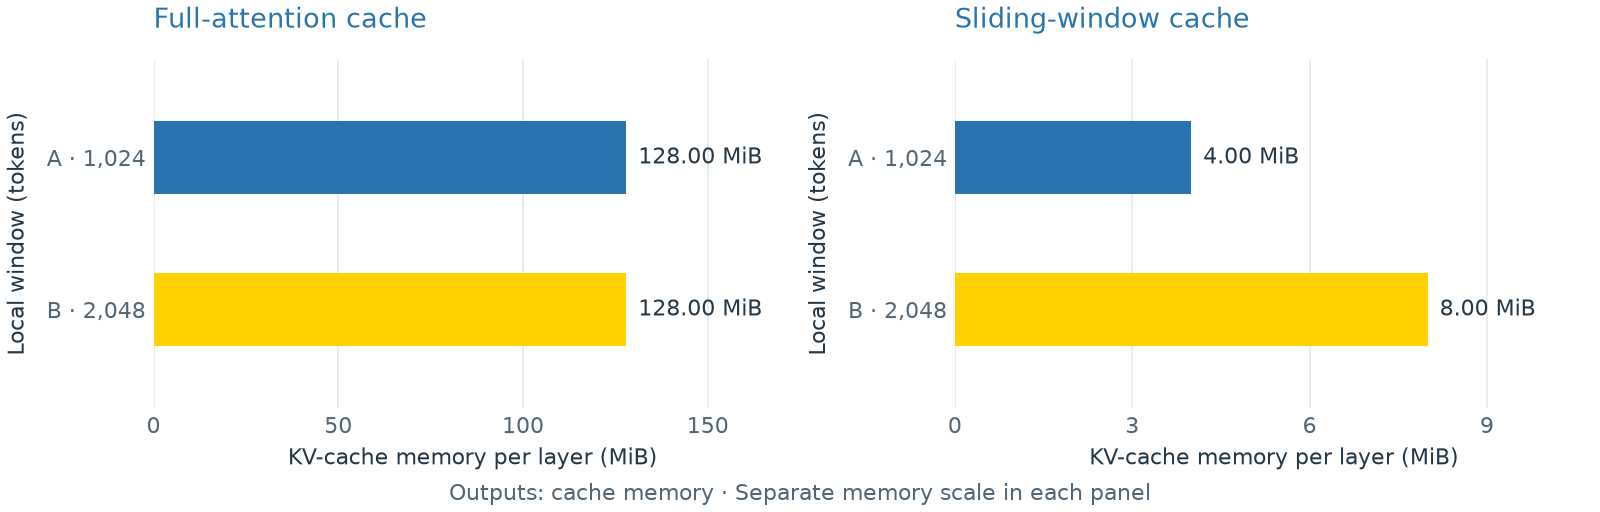

In [147]:
plot_experiment(1)


### 4.3. Experiment: Short context


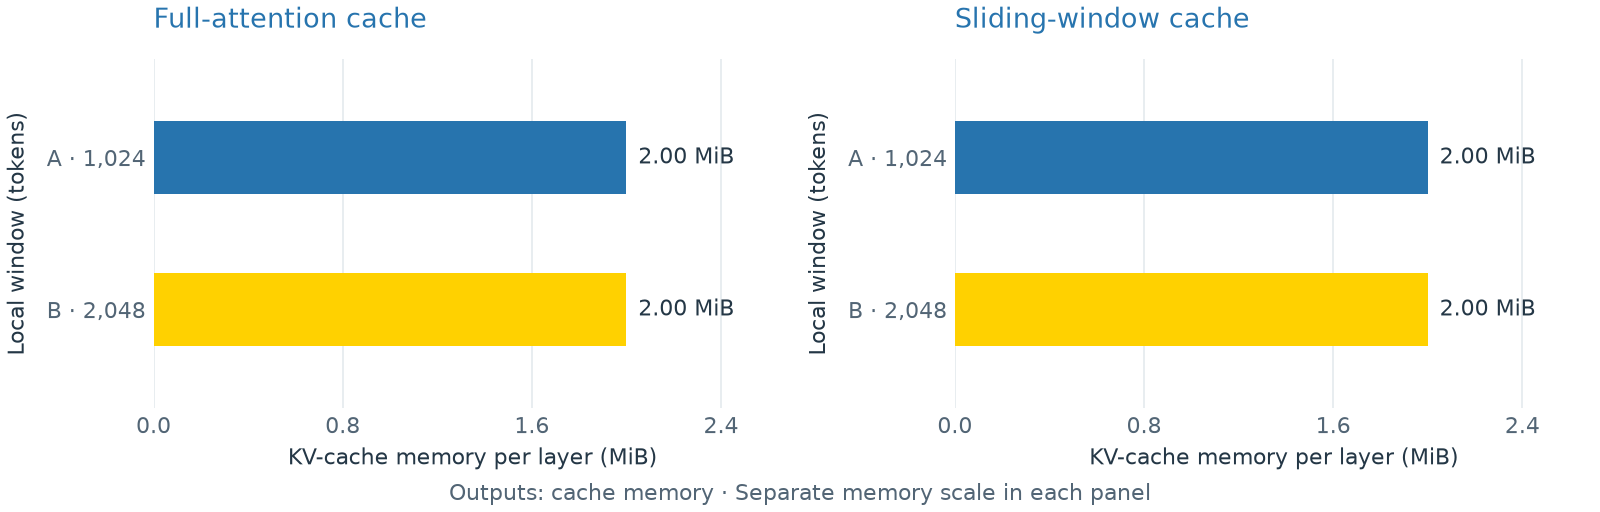

In [148]:
plot_experiment(2)


## 5. Setting up RAPID-LLM

We start with the repository's **Llama 3.1 8B example on one simulated A100 80 GB GPU**. This gives us a full-attention baseline before adding sliding-window attention.

RAPID-LLM reads two files: **model YAML** describes the model and workload; **hardware YAML** describes the GPU, precision, and parallelism. The analytical backend runs on this computer without an NVIDIA GPU. [Repository setup](https://github.com/nanocad-lab/Rapid-LLM/blob/339ef6ab9fe9b38df3e1d1674ef55121792aa421/README.md)

### 5.1. Setup inputs


In [149]:
from pathlib import Path

# Keep the notebook's Python environment and the simulator's environment separate.
project_root = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "sliding_window_start.ipynb").exists()
)
rapid_repo = project_root / "Rapid-LLM"
rapid_python = project_root / ".rapid-venv" / "bin" / "python"
rapid_output = project_root / "runs" / "rapid"
rapid_model = "configs/model-config/Llama3.1-8B_inf.yaml"
rapid_hardware = "configs/hardware-config/a100_80GB_no_parallelism.yaml"


Item,Setting
Repository revision,339ef6a
Simulator Python,Python 3.12.13
Model file,configs/model-config/Llama3.1-8B_inf.yaml
Hardware file,configs/hardware-config/a100_80GB_no_parallelism.yaml
Backend,Analytical · one simulated GPU
Saved runs,runs/rapid/


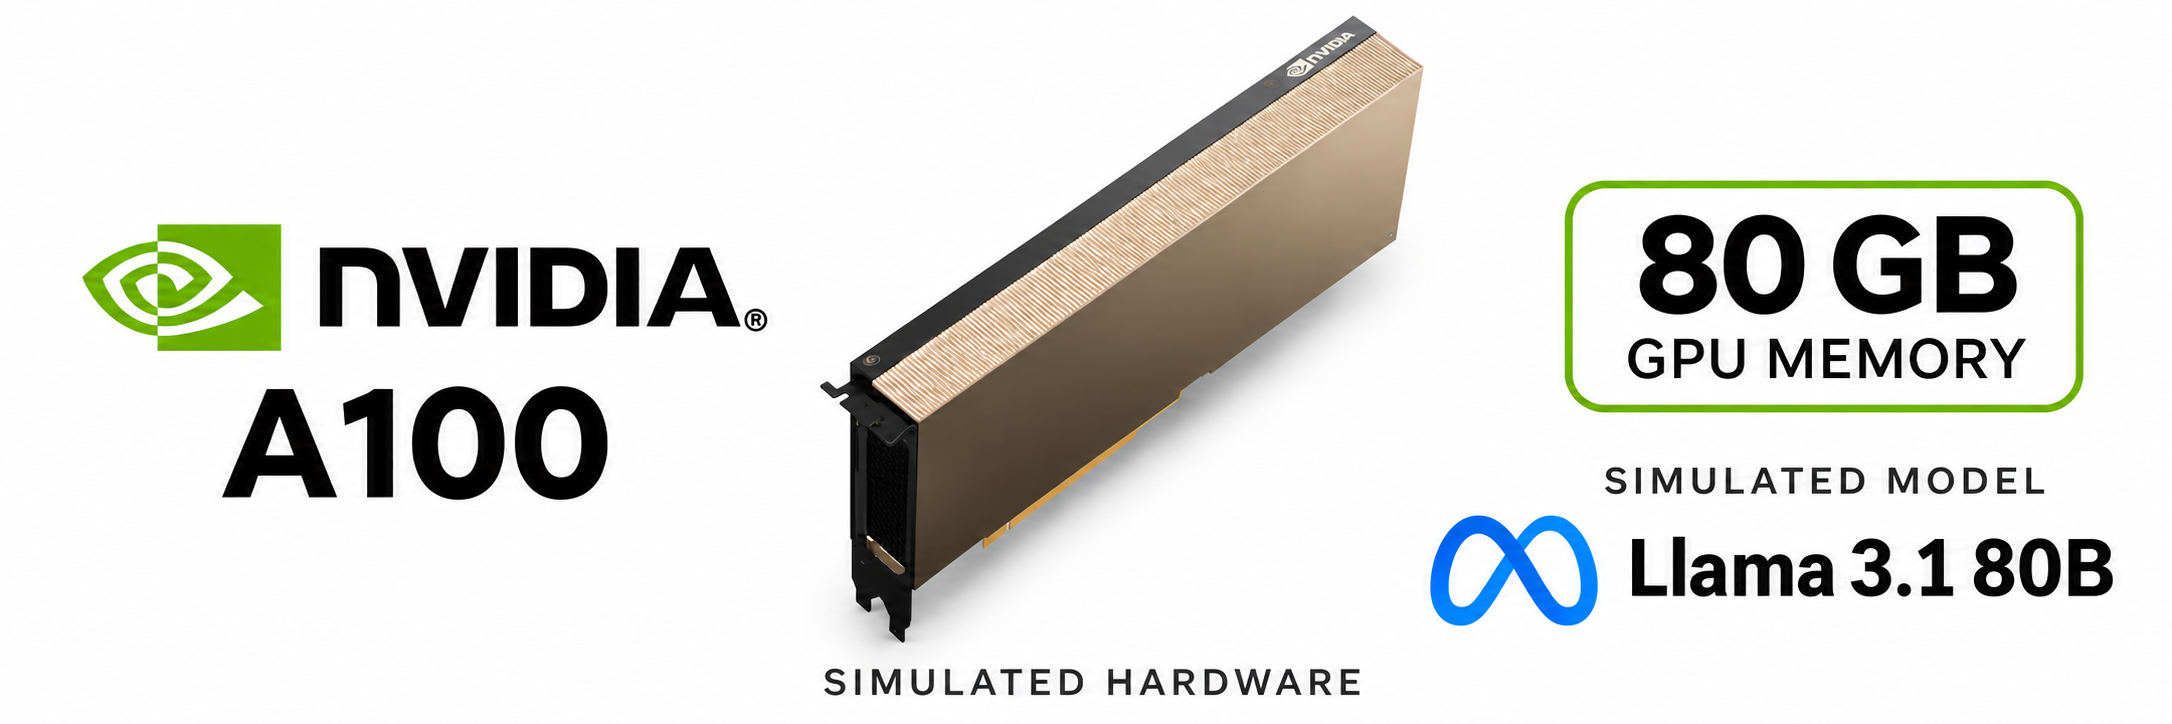

In [150]:
import json
import shutil
import subprocess
from time import perf_counter

if not (rapid_repo / "run_perf.py").exists():
    raise FileNotFoundError("Place the RAPID-LLM repository in the project's Rapid-LLM folder.")
if not rapid_python.exists():
    setup_python = shutil.which("python3.12")
    if setup_python is None:
        raise RuntimeError("Install Python 3.12, then rerun this setup cell.")
    subprocess.run([setup_python, "-m", "venv", str(rapid_python.parent.parent)], check=True)

# Install analytical dependencies only when the simulator imports are missing.
probe = subprocess.run(
    [str(rapid_python), "-c", "import pandas, yaml, numpy, graphviz, pydot, google.protobuf"],
    capture_output=True, text=True,
)
if probe.returncode:
    subprocess.run([
        str(rapid_python), "-m", "pip", "install", "-r",
        str(project_root / "requirements-rapid-analytical.txt"),
    ], check=True, capture_output=True, text=True)


def run_rapid_case(prompt=None, decode=None, batch=None, window=None, interval=4, sample_every=None,
                   model=None, hardware=None, hbm_bandwidth=None, hbm_capacity=None):
    command = [
        str(rapid_python), str(project_root / "scripts" / "rapid_experiment.py"),
        "--repo", str(rapid_repo), "--output-root", str(rapid_output),
        "--model", str(model or rapid_model), "--hardware", str(hardware or rapid_hardware),
    ]
    for flag, value in [("--prompt", prompt), ("--decode", decode), ("--batch", batch),
                        ("--window", window), ("--interval", interval), ("--sample-every", sample_every),
                        ("--hbm-bandwidth", hbm_bandwidth), ("--hbm-capacity", hbm_capacity)]:
        if value is not None:
            command.extend([flag, str(value)])
    completed = subprocess.run(command, capture_output=True, text=True, timeout=360)
    if completed.returncode:
        raise RuntimeError(completed.stderr[-3000:])
    return json.loads(completed.stdout)


def run_rapid_sweep(cases, title):
    rows = []
    for index, inputs in enumerate(cases, start=1):
        window = inputs.get("window")
        attention = "full attention" if window is None else f"window {window:,}"
        print(f"{title} {index}/{len(cases)}: prompt {inputs['prompt']:,}, "
              f"batch {inputs['batch']}, {attention} ... ", end="", flush=True)
        started = perf_counter()
        row = run_rapid_case(**inputs)
        rows.append(row)
        state = "saved result" if row.get("cached") else "completed"
        print(f"{state} ({perf_counter()-started:.1f}s)", flush=True)
    return rows


rapid_commit = subprocess.check_output(
    ["git", "-C", str(rapid_repo), "rev-parse", "--short", "HEAD"], text=True,
).strip()
show_table(
    "RAPID-LLM setup",
    ["Item", "Setting"],
    [
        ("Repository revision", rapid_commit),
        ("Simulator Python", subprocess.check_output([str(rapid_python), "--version"], text=True).strip()),
        ("Model file", rapid_model),
        ("Hardware file", rapid_hardware),
        ("Backend", "Analytical · one simulated GPU"),
        ("Saved runs", "runs/rapid/"),
    ],
)


display(Image(filename=str(
    project_root / "generated_images" / "exec-42a40889-ff50-4f82-a0ab-7ee0812aa36f.png"
)))

### 5.2. First simulator run

The example processes a **1,024-token prompt** and generates **1,024 tokens** for one conversation. RAPID-LLM uses `seq_len = prompt tokens + generated tokens`, so this example has `seq_len = 2,048`.


In [151]:
rapid_baseline = run_rapid_case()
model_shape = rapid_baseline["model"]["model_param"]
show_table(
    "Full-attention baseline · simulator predictions",
    ["Output", "Value"],
    [
        ("Model dimensions", f"{model_shape['num_layers']} layers · {model_shape['attention']['kv_heads']} KV heads"),
        ("Prompt / generated tokens", f"{rapid_baseline['prompt_tokens']:,} / {rapid_baseline['decode_tokens']:,}"),
        ("Prompt processing time", f"{rapid_baseline['prefill_s']:.3f} s"),
        ("Time to first token", f"{rapid_baseline['ttft_s']:.3f} s"),
        ("Token generation time", f"{rapid_baseline['decode_s']:.3f} s"),
        ("Average generation rate per conversation", f"{rapid_baseline['per_user_tok_s']:.1f} tokens/s"),
        ("Peak GPU memory", f"{rapid_baseline['peak_gib']:.2f} GiB"),
        ("Fits GPU memory", "Yes" if rapid_baseline["fits"] else "No"),
    ],
    note="Predictions from RAPID-LLM; no physical A100 was measured.",
)


Output,Value
Model dimensions,32 layers · 8 KV heads
Prompt / generated tokens,"1,024 / 1,024"
Prompt processing time,0.064 s
Time to first token,0.076 s
Token generation time,12.462 s
Average generation rate per conversation,82.2 tokens/s
Peak GPU memory,15.85 GiB
Fits GPU memory,Yes


## 6. Choosing the inputs

We change **one input at a time** so its effect is easy to see. Keep the same model, GPU, BF16 precision, and 256 generated tokens; first vary prompt length, then vary batch size.

### 6.1. Input strategy


In [152]:
# Inputs for the simulator experiments.
prompt_lengths = [512, 2_048, 8_192, 32_768]
batch_sizes = [1, 2, 4, 8]
generated_tokens = 256
reference_prompt_tokens = 8_192
reference_batch_size = 1

# Window inputs for the main experiment in Section 6.4.
planned_windows = [512, 1_024, 2_048, 4_096]


Experiment,Changed input,Held fixed,Why these values?
Longer prompts,"512, 2,048, 8,192, 32,768 tokens",Batch 1; generate 256 tokens,Cover short through long context
More conversations,"1, 2, 4, 8","Prompt 8,192; generate 256 tokens",Double the workload each step
Window comparison,"512, 1,024, 2,048, 4,096 tokens",Same model and local/global layer pattern,Compare progressively larger windows


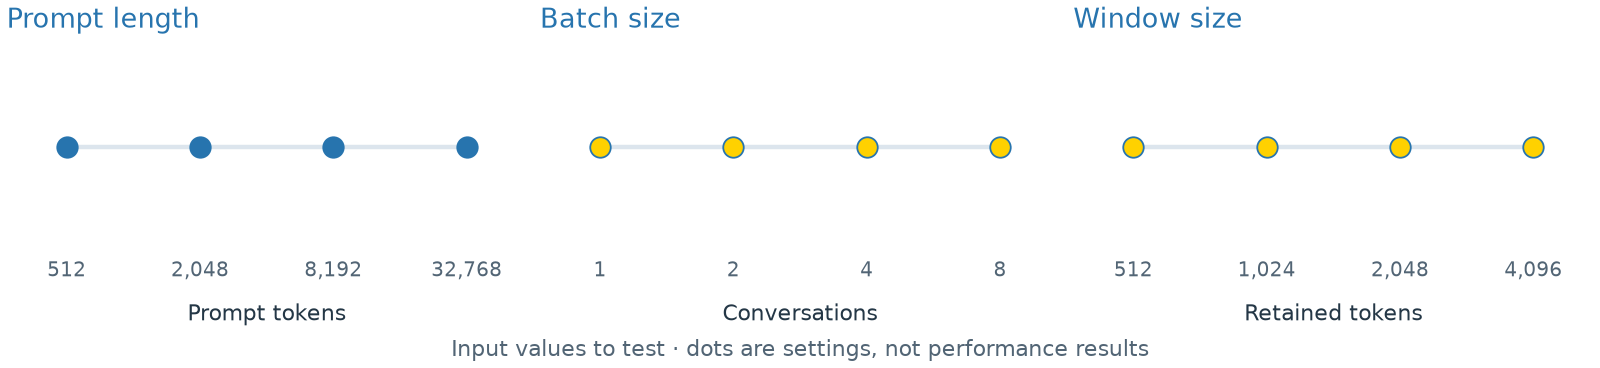

In [153]:
show_table(
    "Inputs we will vary",
    ["Experiment", "Changed input", "Held fixed", "Why these values?"],
    [
        ("Longer prompts", ", ".join(f"{v:,}" for v in prompt_lengths) + " tokens",
         f"Batch {reference_batch_size}; generate {generated_tokens} tokens", "Cover short through long context"),
        ("More conversations", ", ".join(str(v) for v in batch_sizes),
         f"Prompt {reference_prompt_tokens:,}; generate {generated_tokens} tokens", "Double the workload each step"),
        ("Window comparison", ", ".join(f"{v:,}" for v in planned_windows) + " tokens",
         "Same model and local/global layer pattern", "Compare progressively larger windows"),
    ],
)

input_figure = Figure(figsize=(10, 2.3), facecolor="white", layout="constrained")
for ax, values, title, unit, color in zip(
    input_figure.subplots(1, 3),
    [prompt_lengths, batch_sizes, planned_windows],
    ["Prompt length", "Batch size", "Window size"],
    ["Prompt tokens", "Conversations", "Retained tokens"],
    [UCLA_BLUE, UCLA_GOLD, UCLA_GOLD],
):
    ax.set_xscale("log", base=2)
    ax.plot([min(values), max(values)], [1, 1], color="#dce5ed", linewidth=2, zorder=1)
    ax.scatter(values, [1] * len(values), s=85, color=color, edgecolor=UCLA_BLUE, linewidth=0.8, zorder=2)
    ax.set_xticks(values, [f"{value:,}" for value in values])
    ax.minorticks_off()
    ax.set_yticks([])
    ax.set_ylim(0.65, 1.35)
    ax.margins(x=0.15)
    ax.set_title(title, color=UCLA_BLUE, loc="left", fontsize=12)
    ax.set_xlabel(unit, color="#243746", labelpad=10)
    ax.tick_params(axis="x", length=0, labelsize=9, colors="#526575")
    for spine in ax.spines.values():
        spine.set_visible(False)
input_figure.supxlabel("Input values to test · dots are settings, not performance results", color="#526575", fontsize=10)
buffer = BytesIO()
input_figure.savefig(buffer, format="png", dpi=160, facecolor="white")
display(Image(data=buffer.getvalue(), width=1000))


The prompt sizes grow by four each step to cover a wide range with a few runs. Batch and window sizes double each step.


### 6.2. Experiment: Longer prompts


Longer prompts 1/4: prompt 512, batch 1, full attention ... saved result (0.2s)
Longer prompts 2/4: prompt 2,048, batch 1, full attention ... saved result (0.2s)
Longer prompts 3/4: prompt 8,192, batch 1, full attention ... saved result (0.2s)
Longer prompts 4/4: prompt 32,768, batch 1, full attention ... saved result (0.2s)


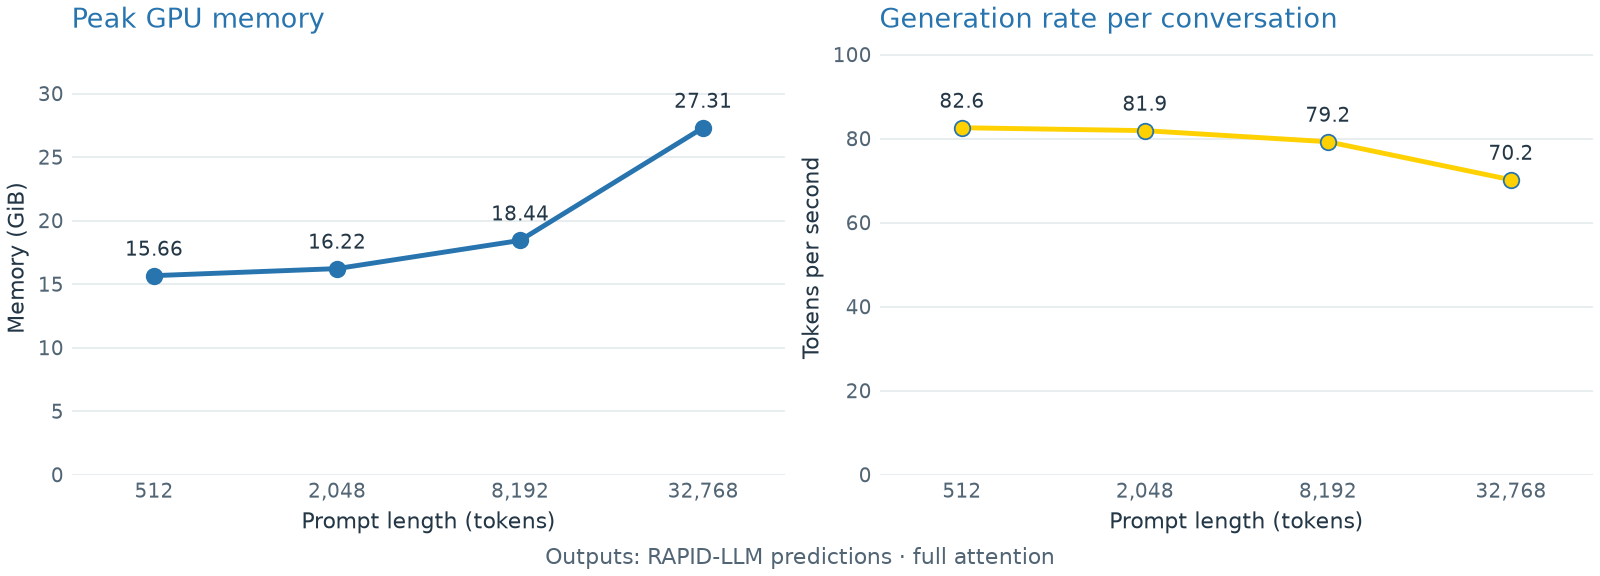

In [154]:
# Define the shared plotting helper, then run and display this experiment below.
def plot_rapid_sweep(rows, x_key, x_label, rate_key, rate_title, fixed):
    """Display memory and generation-rate plots for a completed sweep."""
    x_values = [row[x_key] for row in rows]
    display(HTML(
        '<p style="max-width:1000px; font-family:system-ui,sans-serif; color:#FFFFFF;">'
        f'<strong>Input changed:</strong> {escape(x_label)}. '
        f'<strong>Held fixed:</strong> {escape(fixed)}</p>'
    ))
    figure = Figure(figsize=(10, 3.6), facecolor="white", layout="constrained")
    for ax, key, title, unit, color in zip(
        figure.subplots(1, 2), ["peak_gib", rate_key],
        ["Peak GPU memory", rate_title], ["Memory (GiB)", "Tokens per second"],
        [UCLA_BLUE, UCLA_GOLD],
    ):
        y_values = [row[key] if key == "peak_gib" or row["fits"] else float("nan") for row in rows]
        ax.plot(x_values, y_values, color=color, marker="o", linewidth=2.2,
                markersize=7, markeredgecolor=UCLA_BLUE, markeredgewidth=0.8)
        ax.set_xscale("log", base=2)
        ax.set_xticks(x_values, [f"{value:,}" for value in x_values])
        ax.minorticks_off()
        ax.set_xlabel(x_label, color="#243746")
        ax.set_ylabel(unit, color="#243746")
        ax.set_title(title, color=UCLA_BLUE, loc="left", fontsize=12)
        finite = [value for value in y_values if value == value]
        ax.set_ylim(0, max(finite) * 1.25 if finite else 1)
        ax.margins(x=0.15)
        ax.grid(axis="y", color="#e6ebef")
        ax.set_axisbelow(True)
        ax.tick_params(length=0, colors="#526575", labelsize=9)
        for spine in ax.spines.values():
            spine.set_visible(False)
        for x, y in zip(x_values, y_values):
            if y == y:
                ax.annotate(f"{y:.2f}" if key == "peak_gib" else f"{y:.1f}",
                            (x, y), xytext=(0, 9), textcoords="offset points",
                            ha="center", color="#243746", fontsize=9)
    figure.supxlabel("Outputs: RAPID-LLM predictions · full attention", fontsize=10, color="#526575")
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=160, facecolor="white")
    display(Image(data=buffer.getvalue(), width=1000))
    infeasible = sum(not row["fits"] for row in rows)
    if infeasible:
        display(HTML(f"<p style='color:#FFFFFF;'>{infeasible} cases exceed memory capacity; their generation rates are omitted.</p>"))


prompt_results = run_rapid_sweep(
    [dict(prompt=tokens, decode=generated_tokens, batch=reference_batch_size)
     for tokens in prompt_lengths], "Longer prompts",
)
plot_rapid_sweep(
    prompt_results, "prompt_tokens", "Prompt length (tokens)",
    "per_user_tok_s", "Generation rate per conversation",
    f"batch {reference_batch_size}, {generated_tokens} generated tokens, same model and GPU",
)
first, last = prompt_results[0], prompt_results[-1]
display(HTML(
    '<p style="max-width:1000px; font-family:system-ui,sans-serif; color:#FFFFFF; line-height:1.5;">'
    f"Increasing the prompt from {first['prompt_tokens']:,} to {last['prompt_tokens']:,} tokens "
    f"changes peak memory from {first['peak_gib']:.2f} to {last['peak_gib']:.2f} GiB "
    f"and generation rate from {first['per_user_tok_s']:.1f} to {last['per_user_tok_s']:.1f} tokens/s. "
    "Full attention retains more past tokens as the context grows.</p>"
))


### 6.3. Experiment: More conversations


More conversations 1/4: prompt 8,192, batch 1, full attention ... saved result (0.2s)
More conversations 2/4: prompt 8,192, batch 2, full attention ... saved result (0.2s)
More conversations 3/4: prompt 8,192, batch 4, full attention ... saved result (0.2s)
More conversations 4/4: prompt 8,192, batch 8, full attention ... saved result (0.2s)


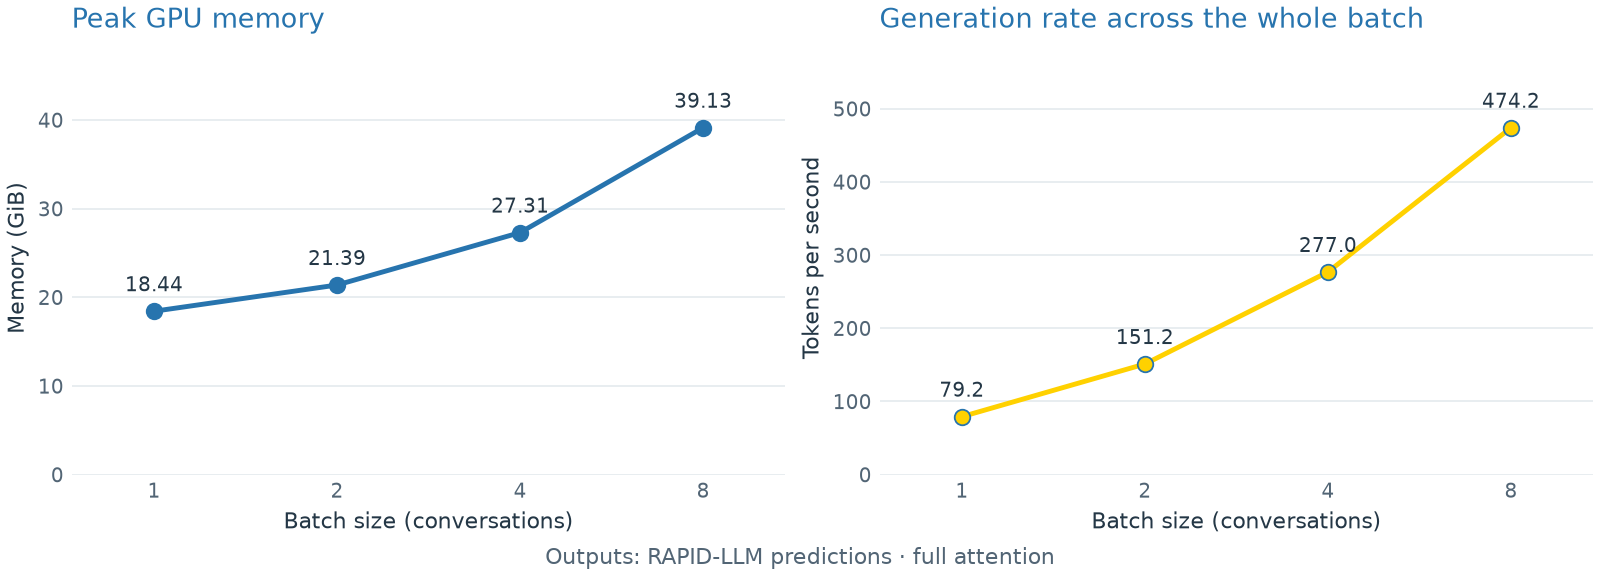

In [155]:
batch_results = run_rapid_sweep(
    [dict(prompt=reference_prompt_tokens, decode=generated_tokens, batch=batch)
     for batch in batch_sizes], "More conversations",
)
plot_rapid_sweep(
    batch_results, "batch_size", "Batch size (conversations)",
    "aggregate_tok_s", "Generation rate across the whole batch",
    f"{reference_prompt_tokens:,}-token prompt, {generated_tokens} generated tokens, same model and GPU",
)
first, last = batch_results[0], batch_results[-1]
display(HTML(
    '<p style="max-width:1000px; font-family:system-ui,sans-serif; color:#FFFFFF; line-height:1.5;">'
    f"Increasing the batch from {first['batch_size']} to {last['batch_size']} conversations "
    f"changes peak memory from {first['peak_gib']:.2f} to {last['peak_gib']:.2f} GiB "
    f"and total generation rate from {first['aggregate_tok_s']:.1f} to {last['aggregate_tok_s']:.1f} tokens/s. "
    f"Per-conversation rate changes from {first['per_user_tok_s']:.1f} to {last['per_user_tok_s']:.1f} tokens/s; "
    "higher total throughput does not necessarily mean faster replies for each user.</p>"
))


### 6.4. Main experiment: Smaller attention windows

**Question:** Can the model use less memory and generate text faster by looking at fewer recent tokens?

We compare full attention with windows of 512, 1,024, 2,048, and 4,096 tokens. In the windowed version, 24 layers look at recent tokens and 8 layers keep the full history. The model size, GPU, and number of generated tokens stay the same.

We report **total GPU memory** and **memory used to save conversation history (the KV cache)** separately. A large reduction in history memory leads to a smaller reduction in total memory because model weights and other working data still need space.

These are simulations using Llama 3.1 8B dimensions on one A100. The windowed version is a hypothetical model; answer quality is not measured. Prompt-processing compute time stays the same in both versions, so speed comparisons concern text generation.


In [156]:
# Main experiment inputs. Keep these separate from plotting code.
main_windows = planned_windows.copy()
main_window = 1_024                    # Window used in the main comparison plots
main_interval = 4                      # Every fourth layer is global
main_prompt_lengths = prompt_lengths.copy()
main_batch_sizes = sorted(set(batch_sizes + [16, 24, 32]))
main_batch_prompt = reference_prompt_tokens
main_decode_tokens = generated_tokens
main_sample_every = 32                 # Also sample either side of window saturation


### 6.5. Longer conversations


Full attention 1/4: prompt 512, batch 1, full attention ... saved result (0.3s)
Full attention 2/4: prompt 2,048, batch 1, full attention ... saved result (0.2s)
Full attention 3/4: prompt 8,192, batch 1, full attention ... saved result (0.2s)
Full attention 4/4: prompt 32,768, batch 1, full attention ... saved result (0.2s)
Window 512 1/4: prompt 512, batch 1, window 512 ... saved result (0.2s)
Window 512 2/4: prompt 2,048, batch 1, window 512 ... saved result (0.2s)
Window 512 3/4: prompt 8,192, batch 1, window 512 ... saved result (0.2s)
Window 512 4/4: prompt 32,768, batch 1, window 512 ... saved result (0.2s)
Window 1,024 1/4: prompt 512, batch 1, window 1,024 ... saved result (0.2s)
Window 1,024 2/4: prompt 2,048, batch 1, window 1,024 ... saved result (0.2s)
Window 1,024 3/4: prompt 8,192, batch 1, window 1,024 ... saved result (0.2s)
Window 1,024 4/4: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
Window 2,048 1/4: prompt 512, batch 1, window 2,048 ... saved resul

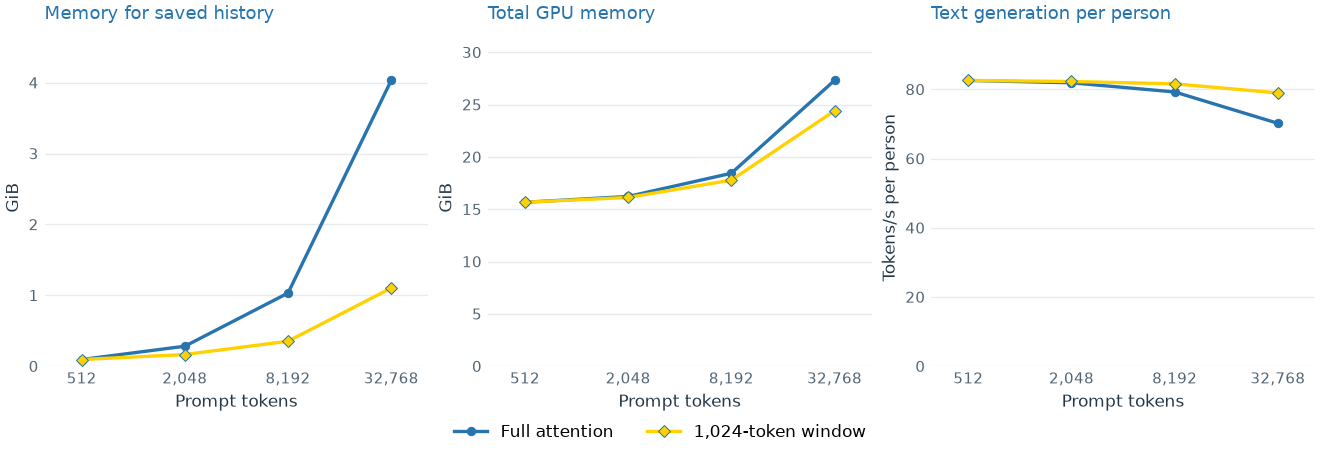

In [157]:
def show_main_comparison(full, local, x_key, x_label, metrics, fixed):
    display(HTML(
        '<p style="max-width:1100px; font-family:system-ui,sans-serif; color:#FFFFFF;">'
        f'<strong>Input changed:</strong> {escape(x_label)}. <strong>Held fixed:</strong> {escape(fixed)}</p>'
    ))
    fig = Figure(figsize=(11, 3.8), layout="constrained", facecolor="white")
    for ax, (key,title,unit) in zip(fig.subplots(1,len(metrics)), metrics):
        for rows, label, color, marker in [
            (full,"Full attention",UCLA_BLUE,"o"),
            (local,f"{main_window:,}-token window",UCLA_GOLD,"D"),
        ]:
            xs=[r[x_key] for r in rows]
            ys=[r[key] if key in ("peak_gib","kv_resident_gib") or r["fits"] else float("nan") for r in rows]
            ax.plot(xs,ys,color=color,marker=marker,linewidth=2,markersize=5,
                    markeredgecolor=UCLA_BLUE,markeredgewidth=.6,label=label)
        ax.set_xscale("log",base=2)
        ax.set_xticks([r[x_key] for r in full],[f"{r[x_key]:,}" for r in full])
        ax.minorticks_off()
        ax.set_xlabel(x_label,fontsize=10,color="#243746")
        ax.set_ylabel(unit,fontsize=10,color="#243746")
        ax.set_title(title,color=UCLA_BLUE,fontsize=11,loc="left")
        finite_values=[r[key] for r in full+local if key in ("peak_gib","kv_resident_gib") or r["fits"]]
        ax.set_ylim(0,max(finite_values)*1.18 if finite_values else 1)
        ax.margins(x=.12)
        if len(full)>5: ax.tick_params(axis="x",labelrotation=35)
        ax.grid(axis="y",color="#e6ebef")
        ax.tick_params(length=0,labelsize=9,colors="#526575")
        for spine in ax.spines.values(): spine.set_visible(False)
        if key=="peak_gib" and any(not r["fits"] for r in full+local):
            ax.axhline(full[0]["capacity_gib"],color="#526575",linestyle=":",linewidth=1)
            ax.text(.02,.96,"GPU capacity shown by dotted line",transform=ax.transAxes,
                    fontsize=8,color="#526575",va="top")
    handles,labels=fig.axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc="outside lower center",ncols=2,frameon=False,fontsize=10)
    output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white")
    fig.clear()
    display(Image(data=output.getvalue(),width=1100))


# Run the context comparisons here, with progress for each simulator case.
main_context_full = run_rapid_sweep(
    [dict(prompt=p, decode=main_decode_tokens, batch=1, sample_every=main_sample_every)
     for p in main_prompt_lengths], "Full attention",
)
main_context_window = {
    window: run_rapid_sweep(
        [dict(prompt=p, decode=main_decode_tokens, batch=1, window=window,
              interval=main_interval, sample_every=main_sample_every)
         for p in main_prompt_lengths], f"Window {window:,}",
    ) for window in main_windows
}

selected_context = main_context_window[main_window]
show_main_comparison(
    main_context_full, selected_context, "prompt_tokens", "Prompt tokens",
    [("kv_resident_gib","Memory for saved history","GiB"),
     ("peak_gib","Total GPU memory","GiB"),
     ("per_user_tok_s","Text generation per person","Tokens/s per person")],
    f"batch 1; {main_decode_tokens} generated tokens; W={main_window:,}; 24 local + 8 global layers",
)
f,l=main_context_full[-1],selected_context[-1]
memory_saved=100*(1-l['peak_gib']/f['peak_gib'])
history_saved=100*(1-l['kv_resident_gib']/f['kv_resident_gib'])
speed_gained=100*(l['per_user_tok_s']/f['per_user_tok_s']-1)
display(HTML(
    '<p style="max-width:1100px; font-family:system-ui,sans-serif; line-height:1.5; color:#FFFFFF;">'
    f"For the {f['prompt_tokens']:,}-token prompt, a {main_window:,}-token window used "
    f"<strong>{memory_saved:.1f}% less total GPU memory</strong> and generated text "
    f"<strong>{speed_gained:.1f}% faster per person</strong> than full attention. "
    f"Memory used to save conversation history fell by {history_saved:.1f}%.</p>"
))


### 6.6. Smaller windows


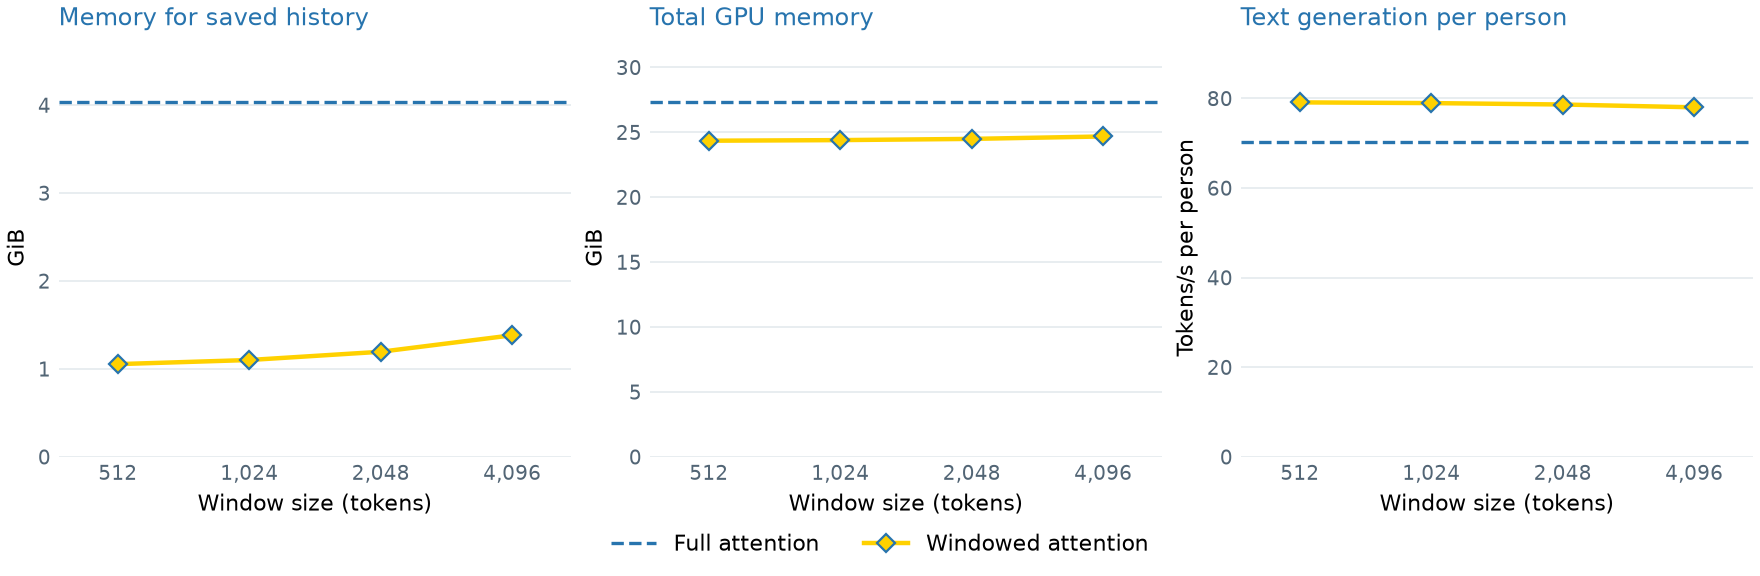

Window size,Less total GPU memory,Less history memory,Faster text generation
512 tokens,10.8%,73.8%,12.7%
"1,024 tokens",10.6%,72.7%,12.5%
"2,048 tokens",10.3%,70.3%,12.1%
"4,096 tokens",9.6%,65.7%,11.2%


In [158]:
window_rows=[main_context_window[w][-1] for w in main_windows]
full_reference=main_context_full[-1]
fig=Figure(figsize=(11,3.6),layout="constrained",facecolor="white")
for ax,key,title,unit in zip(fig.subplots(1,3),
    ["kv_resident_gib","peak_gib","per_user_tok_s"],
    ["Memory for saved history","Total GPU memory","Text generation per person"],
    ["GiB","GiB","Tokens/s per person"]):
    ax.axhline(full_reference[key],color=UCLA_BLUE,linestyle="--",label="Full attention")
    ax.plot(main_windows,[r[key] for r in window_rows],color=UCLA_GOLD,marker="D",
            markeredgecolor=UCLA_BLUE,linewidth=2,label="Windowed attention")
    ax.set_xscale("log",base=2);ax.set_xticks(main_windows,[f"{w:,}" for w in main_windows]);ax.minorticks_off()
    ax.set_xlabel("Window size (tokens)",fontsize=10)
    ax.set_ylabel(unit,fontsize=10);ax.set_title(title,color=UCLA_BLUE,fontsize=11,loc="left")
    ax.set_ylim(0,max([full_reference[key]]+[r[key] for r in window_rows])*1.18);ax.margins(x=.15);ax.grid(axis="y",color="#e6ebef")
    ax.tick_params(length=0,labelsize=9,colors="#526575")
    for spine in ax.spines.values():spine.set_visible(False)
fig.legend(*fig.axes[0].get_legend_handles_labels(),loc="outside lower center",ncols=2,frameon=False)
output=BytesIO();fig.savefig(output,format="png",dpi=160,facecolor="white");display(Image(data=output.getvalue(),width=1100))
show_table(
    f"Savings versus full attention · {full_reference['prompt_tokens']:,}-token prompt · one person",
    ["Window size", "Less total GPU memory", "Less history memory", "Faster text generation"],
    [(f"{w:,} tokens",f"{100*(1-r['peak_gib']/full_reference['peak_gib']):.1f}%",
      f"{100*(1-r['kv_resident_gib']/full_reference['kv_resident_gib']):.1f}%",
      f"{100*(r['per_user_tok_s']/full_reference['per_user_tok_s']-1):.1f}%")
     for w,r in zip(main_windows,window_rows)],
    note="Every percentage compares against full attention with the same prompt, model size, and GPU.",
)
smallest=min(window_rows,key=lambda r:r['window'])
largest=max(window_rows,key=lambda r:r['window'])
display(HTML(
    '<p style="max-width:1100px; font-family:system-ui,sans-serif; line-height:1.5; color:#FFFFFF;">'
    f"Reducing the window from {largest['window']:,} to {smallest['window']:,} tokens used "
    f"<strong>{100*(1-smallest['peak_gib']/largest['peak_gib']):.1f}% less total GPU memory</strong> "
    f"and {100*(1-smallest['kv_resident_gib']/largest['kv_resident_gib']):.1f}% less history memory. "
    "Both windowed versions already save memory compared with full attention.</p>"
))


### 6.7. Serving more people


Full-attention batches 1/7: prompt 8,192, batch 1, full attention ... saved result (0.2s)
Full-attention batches 2/7: prompt 8,192, batch 2, full attention ... saved result (0.2s)
Full-attention batches 3/7: prompt 8,192, batch 4, full attention ... saved result (0.2s)
Full-attention batches 4/7: prompt 8,192, batch 8, full attention ... saved result (0.2s)
Full-attention batches 5/7: prompt 8,192, batch 16, full attention ... saved result (0.2s)
Full-attention batches 6/7: prompt 8,192, batch 24, full attention ... saved result (0.2s)
Full-attention batches 7/7: prompt 8,192, batch 32, full attention ... saved result (0.2s)
Windowed batches 1/7: prompt 8,192, batch 1, window 1,024 ... saved result (0.2s)
Windowed batches 2/7: prompt 8,192, batch 2, window 1,024 ... saved result (0.2s)
Windowed batches 3/7: prompt 8,192, batch 4, window 1,024 ... saved result (0.2s)
Windowed batches 4/7: prompt 8,192, batch 8, window 1,024 ... saved result (0.2s)
Windowed batches 5/7: prompt 8,192, bat

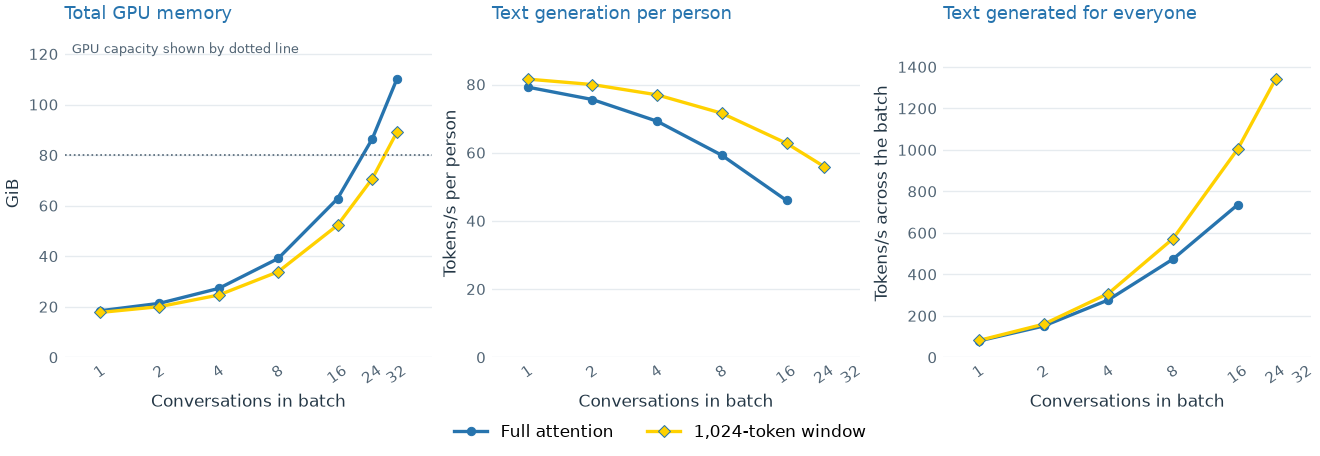

Attention,People served together,GPU memory (GiB),Tokens/s per person,Total tokens/s
Full,16,62.79,46.0,736.3
"Window 1,024",24,70.70,55.9,1341.7


In [159]:
# Run this experiment's cases before drawing its plots.
main_batch_full = run_rapid_sweep(
    [dict(prompt=main_batch_prompt, decode=main_decode_tokens, batch=b,
          sample_every=main_sample_every) for b in main_batch_sizes], "Full-attention batches",
)
main_batch_window = run_rapid_sweep(
    [dict(prompt=main_batch_prompt, decode=main_decode_tokens, batch=b,
          window=main_window, interval=main_interval, sample_every=main_sample_every)
     for b in main_batch_sizes], "Windowed batches",
)

show_main_comparison(
    main_batch_full,main_batch_window,"batch_size","Conversations in batch",
    [("peak_gib","Total GPU memory","GiB"),
     ("per_user_tok_s","Text generation per person","Tokens/s per person"),
     ("aggregate_tok_s","Text generated for everyone","Tokens/s across the batch")],
    f"prompt {main_batch_prompt:,}; {main_decode_tokens} generated tokens; W={main_window:,}; same GPU and layer pattern",
)
full_fits=[r for r in main_batch_full if r['fits']]
local_fits=[r for r in main_batch_window if r['fits']]
show_table(
    "How many people can fit in GPU memory?",
    ["Attention","People served together","GPU memory (GiB)","Tokens/s per person","Total tokens/s"],
    [(label,str(rows[-1]['batch_size']),f"{rows[-1]['peak_gib']:.2f}",f"{rows[-1]['per_user_tok_s']:.1f}",f"{rows[-1]['aggregate_tok_s']:.1f}")
     for label,rows in [("Full",full_fits),(f"Window {main_window:,}",local_fits)] if rows],
    note="These are the largest groups that fit among the sizes we tried. Rates are shown only for groups that fit in GPU memory.",
)

# Save the complete result grid, including infeasible cases and run IDs.
all_main_rows=main_context_full+[r for rows in main_context_window.values() for r in rows]+main_batch_full+main_batch_window
main_result_dir=project_root/"runs"/"main_experiment"
main_result_dir.mkdir(parents=True,exist_ok=True)
_ = (main_result_dir/"results.json").write_text(json.dumps(all_main_rows,indent=2)+"\n")


Each person can receive text more slowly when more people share the GPU, even while the system produces more text overall. The plots show speed per person and total output separately.


### 6.8. Results

The percentages below summarize the longest prompt in the experiment. Memory savings compare the same model size and workload.


In [160]:
full=main_context_full[-1]
smallest=main_context_window[min(main_windows)][-1]
largest=main_context_window[max(main_windows)][-1]
full_limit=full_fits[-1] if full_fits else None
window_limit=local_fits[-1] if local_fits else None
memory_drop=100*(1-smallest['peak_gib']/full['peak_gib'])
history_drop=100*(1-smallest['kv_resident_gib']/full['kv_resident_gib'])
speed_rise=100*(smallest['per_user_tok_s']/full['per_user_tok_s']-1)
paragraphs=[
    f"<strong>Smaller windows saved memory.</strong> With a {full['prompt_tokens']:,}-token prompt, "
    f"the {smallest['window']:,}-token window used <strong>{memory_drop:.1f}% less total GPU memory</strong> "
    f"than full attention ({full['peak_gib']:.2f} → {smallest['peak_gib']:.2f} GiB). "
    f"The part used to save conversation history fell by {history_drop:.1f}%.",
    f"<strong>Text generation was faster.</strong> Each person received <strong>{speed_rise:.1f}% more tokens per second</strong> "
    f"({full['per_user_tok_s']:.1f} → {smallest['per_user_tok_s']:.1f}).",
    f"<strong>Further shrinking the window gave smaller gains.</strong> Going from a {largest['window']:,}-token window "
    f"to {smallest['window']:,} saved {100*(1-smallest['peak_gib']/largest['peak_gib']):.1f}% of total GPU memory "
    f"compared with the larger window.",
]
if full_limit and window_limit:
    paragraphs.append(
        f"<strong>More people fit on the same GPU.</strong> For the separate {main_batch_prompt:,}-token prompt experiment, "
        f"the largest groups that fit were <strong>{full_limit['batch_size']} people with full attention</strong> and "
        f"<strong>{window_limit['batch_size']} with a {main_window:,}-token window</strong>. "
        "These are the largest group sizes we tried that fit, rather than exact capacity limits."
    )
display(HTML(
    '<div style="max-width:1000px; font-family:system-ui,sans-serif; line-height:1.6; color:#FFFFFF; '
    f'border-left:4px solid {UCLA_GOLD}; padding-left:18px;">'
    + ''.join(f'<p>{paragraph}</p>' for paragraph in paragraphs)
    + '</div>'
))


These are simulator predictions for our chosen layer pattern. Answer quality was not measured, and prompt-processing compute time was kept the same; this experiment does not establish a faster prompt-processing method.


## 7. Comparing with published results

We compare two separate things: the **cache-memory reduction reported by Mistral's authors**, and **published A100 timing measurements for our full-attention baseline**. Agreement on memory does not automatically establish timing accuracy.

### 7.1. Published memory result

The [Mistral 7B paper, Section 2](https://arxiv.org/html/2310.06825v1#S2) reports **8× less KV-cache memory** for a 4,096-position rolling window at 32K context. We use its published dimensions and all-local attention, rather than our earlier three-local/one-global pattern. [Official model configuration](https://huggingface.co/mistralai/Mistral-7B-v0.1/raw/main/config.json)


In [161]:
# Published-reference inputs, kept separate from the display code.
published = json.loads((project_root/"data/published_references.json").read_text())
study_configs = project_root/"configs/studies"
reference_hardware = study_configs/"a100_sxm.yaml"
reference_model = study_configs/"mistral_7b_v01.yaml"
validation_decode_tokens = 256
published_context = published["memory"]["context_tokens"]
published_window = published["memory"]["window_tokens"]


Published memory comparison 1/2: prompt 32,512, batch 1, full attention ... saved result (0.2s)
Published memory comparison 2/2: prompt 32,512, batch 1, window 4,096 ... saved result (0.2s)


Quantity,Result
Published cache reduction,8×
RAPID-LLM cache reduction,8×
Difference from published ratio,0.00%
Simulated full / window cache,4.00 / 0.50 GiB


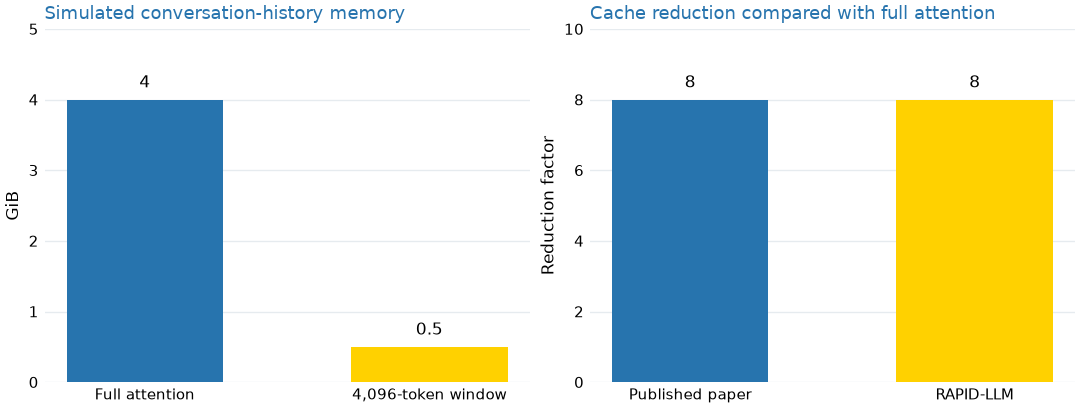

In [162]:
memory_cases = run_rapid_sweep([
    dict(prompt=published_context-validation_decode_tokens,decode=validation_decode_tokens,batch=1,
         model=reference_model,hardware=reference_hardware,sample_every=32),
    dict(prompt=published_context-validation_decode_tokens,decode=validation_decode_tokens,batch=1,
         model=reference_model,hardware=reference_hardware,window=published_window,interval=0,sample_every=32),
], "Published memory comparison")
cache_full,cache_window=memory_cases
cache_ratio=cache_full['kv_resident_bytes']/cache_window['kv_resident_bytes']
reported_ratio=published['memory']['reported_cache_reduction']
show_table("Mistral 7B · final context exactly 32,768 positions",["Quantity","Result"],[
    ("Published cache reduction",f"{reported_ratio:g}×"),
    ("RAPID-LLM cache reduction",f"{cache_ratio:g}×"),
    ("Difference from published ratio",f"{100*abs(cache_ratio/reported_ratio-1):.2f}%"),
    ("Simulated full / window cache",f"{cache_full['kv_resident_gib']:.2f} / {cache_window['kv_resident_gib']:.2f} GiB"),
])
fig=Figure(figsize=(9,3.4),layout="constrained",facecolor="white")
left,right=fig.subplots(1,2)
for ax,labels,values,title,unit in [
    (left,["Full attention","4,096-token window"],[cache_full['kv_resident_gib'],cache_window['kv_resident_gib']],"Simulated conversation-history memory","GiB"),
    (right,["Published paper","RAPID-LLM"],[reported_ratio,cache_ratio],"Cache reduction compared with full attention","Reduction factor"),
]:
    bars=ax.bar(labels,values,color=[UCLA_BLUE,UCLA_GOLD],width=.55)
    ax.bar_label(bars,labels=[f"{v:g}" for v in values],padding=5)
    ax.set_title(title,color=UCLA_BLUE,loc="left",fontsize=11);ax.set_ylabel(unit)
    ax.set_ylim(0,max(values)*1.25);ax.grid(axis="y",color="#e6ebef");ax.set_axisbelow(True)
    ax.tick_params(length=0,labelsize=9)
    for spine in ax.spines.values():spine.set_visible(False)
output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white");fig.clear();display(Image(data=output.getvalue(),width=1000))
display(HTML(f"<p style='color:#FFFFFF;'>RAPID-LLM reproduced the paper's <strong>{cache_ratio:g}× cache reduction</strong>, or <strong>{100*(1-1/cache_ratio):.1f}% less history memory</strong>. This reproduces the published cache result; it does not mean an eightfold speed improvement.</p>"))


### 7.2. Published timing measurements

[Koyeb's published table](https://www.koyeb.com/deploy/llama-3-1-8b-instruct#benchmarks) gives measured A100 SXM results for Llama 3.1 8B Instruct. We use **all three single-conversation A100 SXM rows**, with their actual recorded input/output counts, and compare wall-clock time with simulated **prompt processing plus generation time**.

The simulator assumes BF16. The source does not fully specify precision, serving-kernel versions, or system overhead, so this is an approximate baseline comparison. We do not fit parameters to these measurements or use their throughput column as a decode-only measurement. Reference values and URLs are saved in `data/published_references.json`.


Published timing comparison 1/3: prompt 1,484, batch 1, full attention ... saved result (0.2s)
Published timing comparison 2/3: prompt 2,948, batch 1, full attention ... saved result (0.2s)
Published timing comparison 3/3: prompt 11,525, batch 1, full attention ... saved result (0.2s)


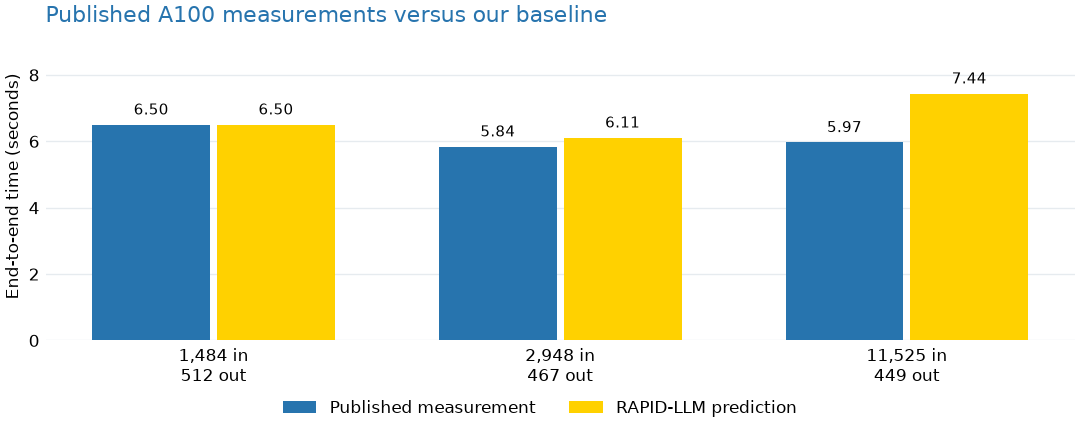

Input / output tokens,Published time,Simulated time,Time difference
"1,484 / 512",6.50 s,6.50 s,+0.0%
"2,948 / 467",5.84 s,6.11 s,+4.6%
"11,525 / 449",5.97 s,7.44 s,+24.6%


In [163]:
timing_cases=run_rapid_sweep([
    dict(prompt=r['input_tokens'],decode=r['output_tokens'],batch=1,hardware=reference_hardware,sample_every=32)
    for r in published['timing']['rows']
], "Published timing comparison")
measured_times=[r['wall_s'] for r in published['timing']['rows']]
predicted_times=[r['prefill_s']+r['decode_s'] for r in timing_cases]
timing_errors=[100*(prediction/measurement-1) for prediction,measurement in zip(predicted_times,measured_times)]
mean_timing_error=sum(abs(e) for e in timing_errors)/len(timing_errors)
labels=[f"{r['input_tokens']:,} in\n{r['output_tokens']:,} out" for r in published['timing']['rows']]
fig=Figure(figsize=(9,3.6),layout="constrained",facecolor="white");ax=fig.subplots()
xs=list(range(len(labels)))
for offset,values,color,label in [(-.18,measured_times,UCLA_BLUE,"Published measurement"),(.18,predicted_times,UCLA_GOLD,"RAPID-LLM prediction")]:
    bars=ax.bar([x+offset for x in xs],values,width=.34,color=color,label=label)
    ax.bar_label(bars,fmt="%.2f",padding=4,fontsize=9)
ax.set_xticks(xs,labels);ax.set_ylabel("End-to-end time (seconds)")
ax.set_title("Published A100 measurements versus our baseline",color=UCLA_BLUE,loc="left",fontsize=13)
ax.set_ylim(0,max(measured_times+predicted_times)*1.25);ax.grid(axis="y",color="#e6ebef");ax.set_axisbelow(True)
ax.tick_params(length=0)
for spine in ax.spines.values():spine.set_visible(False)
fig.legend(*ax.get_legend_handles_labels(),loc="outside lower center",ncols=2,frameon=False)
output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white");fig.clear();display(Image(data=output.getvalue(),width=1000))
show_table("Timing differences · all three published single-person cases",["Input / output tokens","Published time","Simulated time","Time difference"],[
    (f"{ref['input_tokens']:,} / {ref['output_tokens']:,}",f"{measurement:.2f} s",f"{prediction:.2f} s",f"{error:+.1f}%")
    for ref,measurement,prediction,error in zip(published['timing']['rows'],measured_times,predicted_times,timing_errors)
])
display(HTML(f"<p style='color:#FFFFFF;'>The average absolute timing difference is <strong>{mean_timing_error:.1f}%</strong>; the largest is <strong>{max(abs(e) for e in timing_errors):.1f}%</strong>. Positive differences mean the simulator predicts a longer runtime.</p>"))
validation_dir=project_root/"runs/published_comparison";validation_dir.mkdir(parents=True,exist_ok=True)
_=(validation_dir/"results.json").write_text(json.dumps(dict(memory=memory_cases,timing=timing_cases,published=published,
    timing_errors_percent=timing_errors,mean_absolute_timing_error_percent=mean_timing_error),indent=2)+"\n")


## 8. Does hardware change the benefit?

**The byte savings follow the same formula on every GPU. Speed and capacity benefits can still differ.** A GPU may be limited by moving data, doing calculations, or simply having enough memory. Reducing the window helps these limits by different amounts.

### 8.1. Hardware choices

**H100** is useful for studying a faster processor with similar memory capacity. **H200** adds faster memory and more space, which can allow a larger group of conversations. We also change bandwidth or capacity alone to see which resource causes each effect.

| Simulated profile | Memory capacity | Memory bandwidth | Purpose |
|---|---:|---:|---|
| A100 SXM-like | 80 GB | 2.039 TB/s | Reference hardware |
| H100 SXM-like | 80 GB | 3.35 TB/s | More compute and bandwidth, similar capacity |
| H200 SXM-like | 141 GB | 4.8 TB/s | More bandwidth and room for conversations |

In [164]:
# Hardware-study inputs: same model and local/global pattern as the main experiment.
hardware_prompt_tokens=32_768
hardware_decode_tokens=256
hardware_window_tokens=1_024
hardware_interval=4
hardware_sample_every=32
hardware_profiles={name:study_configs/filename for name,filename in [
    ("A100-like","a100_sxm.yaml"),("H100-like","h100_sxm.yaml"),("H200-like","h200_sxm.yaml")
]}
bandwidth_factors=[0.5,1,2,4]
capacity_gb=[40,80,141]
capacity_prompt_tokens=8_192
capacity_batches=[1,4,8,16,24,32,48,64]


### 8.2. Comparing GPU options


A100-like 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
A100-like 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
H100-like 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
H100-like 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
H200-like 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
H200-like 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)


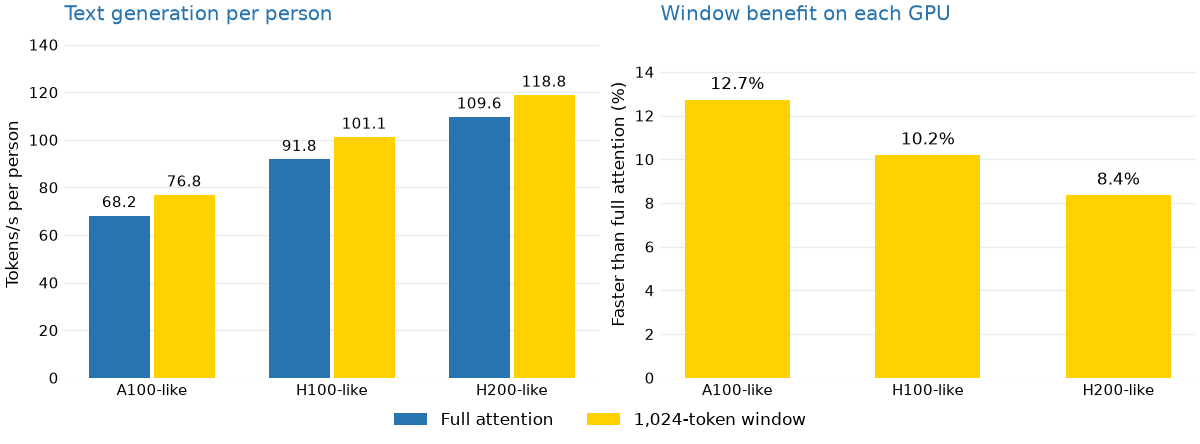

GPU-like profile,Full tokens/s,Window tokens/s,Faster with window,History memory saved
A100-like,68.2,76.8,12.7%,72.7%
H100-like,91.8,101.1,10.2%,72.7%
H200-like,109.6,118.8,8.4%,72.7%


In [165]:
gpu_results={name:run_rapid_sweep([
    dict(prompt=hardware_prompt_tokens,decode=hardware_decode_tokens,batch=1,hardware=config,sample_every=hardware_sample_every),
    dict(prompt=hardware_prompt_tokens,decode=hardware_decode_tokens,batch=1,hardware=config,sample_every=hardware_sample_every,
         window=hardware_window_tokens,interval=hardware_interval),
],name) for name,config in hardware_profiles.items()}
fig=Figure(figsize=(10,3.7),layout="constrained",facecolor="white");left,right=fig.subplots(1,2)
names=list(gpu_results);xs=list(range(len(names)))
for offset,policy,color in [(-.18,0,UCLA_BLUE),(.18,1,UCLA_GOLD)]:
    values=[gpu_results[name][policy]['per_user_tok_s'] for name in names]
    bars=left.bar([x+offset for x in xs],values,width=.34,color=color,label="Full attention" if policy==0 else f"{hardware_window_tokens:,}-token window")
    left.bar_label(bars,fmt="%.1f",padding=3,fontsize=9)
gpu_gains=[100*(gpu_results[name][1]['per_user_tok_s']/gpu_results[name][0]['per_user_tok_s']-1) for name in names]
bars=right.bar(xs,gpu_gains,color=UCLA_GOLD,width=.55);right.bar_label(bars,fmt="%.1f%%",padding=4)
for ax,title,unit in [(left,"Text generation per person","Tokens/s per person"),(right,"Window benefit on each GPU","Faster than full attention (%)")]:
    ax.set_xticks(xs,names);ax.set_ylabel(unit);ax.set_title(title,color=UCLA_BLUE,fontsize=12,loc="left")
    ax.set_ylim(bottom=0,top=(max([r['per_user_tok_s'] for rows in gpu_results.values() for r in rows])*1.23 if ax is left else max(gpu_gains)*1.25))
    ax.grid(axis="y",color="#e6ebef");ax.set_axisbelow(True);ax.tick_params(length=0,labelsize=9)
    for spine in ax.spines.values():spine.set_visible(False)
fig.legend(*left.get_legend_handles_labels(),loc="outside lower center",ncols=2,frameon=False)
output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white");fig.clear();display(Image(data=output.getvalue(),width=1100))
show_table("Same 32,768-token prompt and one person on each GPU",["GPU-like profile","Full tokens/s","Window tokens/s","Faster with window","History memory saved"],[
    (name,f"{rows[0]['per_user_tok_s']:.1f}",f"{rows[1]['per_user_tok_s']:.1f}",f"{100*(rows[1]['per_user_tok_s']/rows[0]['per_user_tok_s']-1):.1f}%",
     f"{100*(1-rows[1]['kv_resident_gib']/rows[0]['kv_resident_gib']):.1f}%") for name,rows in gpu_results.items()
])


### 8.3. Changing only memory bandwidth

Bandwidth means how quickly the GPU can move data. Here capacity and compute stay fixed; only memory bandwidth changes. If both versions remain limited by data movement, their percentage speed difference can stay almost constant—your scaling intuition can be correct in that regime.


Bandwidth 0.5× 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
Bandwidth 0.5× 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
Bandwidth 1× 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
Bandwidth 1× 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
Bandwidth 2× 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
Bandwidth 2× 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)
Bandwidth 4× 1/2: prompt 32,768, batch 1, full attention ... saved result (0.2s)
Bandwidth 4× 2/2: prompt 32,768, batch 1, window 1,024 ... saved result (0.2s)


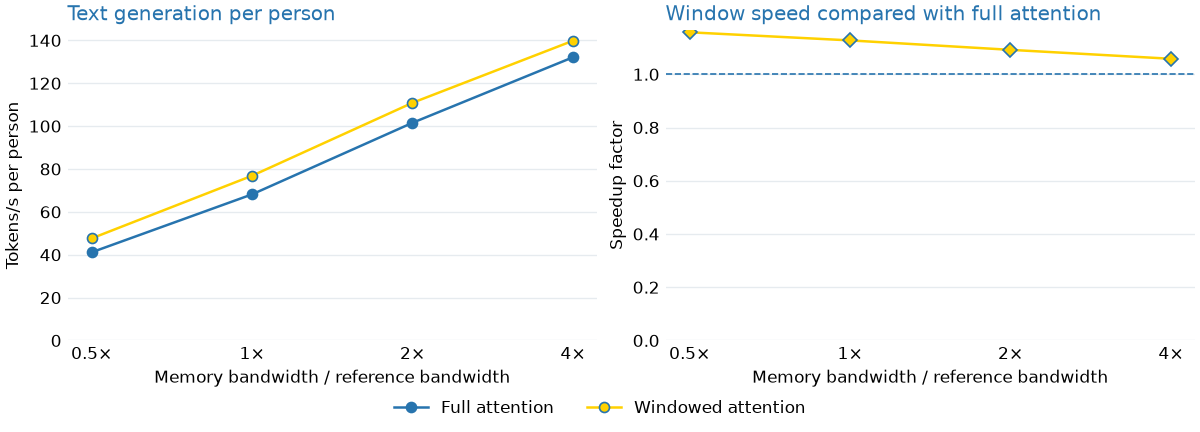

In [166]:
bandwidth_results={factor:run_rapid_sweep([
    dict(prompt=hardware_prompt_tokens,decode=hardware_decode_tokens,batch=1,hardware=reference_hardware,
         hbm_bandwidth=int(2_039_000_000_000*factor),sample_every=hardware_sample_every),
    dict(prompt=hardware_prompt_tokens,decode=hardware_decode_tokens,batch=1,hardware=reference_hardware,
         hbm_bandwidth=int(2_039_000_000_000*factor),sample_every=hardware_sample_every,window=hardware_window_tokens,interval=hardware_interval),
],f"Bandwidth {factor:g}×") for factor in bandwidth_factors}
fig=Figure(figsize=(10,3.6),layout="constrained",facecolor="white");left,right=fig.subplots(1,2)
for policy,color,label in [(0,UCLA_BLUE,"Full attention"),(1,UCLA_GOLD,"Windowed attention")]:
    left.plot(bandwidth_factors,[bandwidth_results[f][policy]['per_user_tok_s'] for f in bandwidth_factors],
              color=color,marker="o",markeredgecolor=UCLA_BLUE,label=label)
ratios=[bandwidth_results[f][1]['per_user_tok_s']/bandwidth_results[f][0]['per_user_tok_s'] for f in bandwidth_factors]
right.plot(bandwidth_factors,ratios,color=UCLA_GOLD,marker="D",markeredgecolor=UCLA_BLUE)
right.axhline(1,color=UCLA_BLUE,linestyle="--",linewidth=1)
for ax,title,unit in [(left,"Text generation per person","Tokens/s per person"),(right,"Window speed compared with full attention","Speedup factor")]:
    ax.set_xscale("log",base=2);ax.set_xticks(bandwidth_factors,[f"{f:g}×" for f in bandwidth_factors]);ax.minorticks_off()
    ax.set_xlabel("Memory bandwidth / reference bandwidth");ax.set_ylabel(unit)
    ax.set_title(title,color=UCLA_BLUE,fontsize=12,loc="left");ax.set_ylim(bottom=0)
    ax.grid(axis="y",color="#e6ebef");ax.tick_params(length=0)
    for spine in ax.spines.values():spine.set_visible(False)
fig.legend(*left.get_legend_handles_labels(),loc="outside lower center",ncols=2,frameon=False)
output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white");fig.clear();display(Image(data=output.getvalue(),width=1100))
display(HTML(f"<p style='color:#FFFFFF;'>Across these bandwidth settings, the window's generation-speed benefit ranged from <strong>{100*(min(ratios)-1):.1f}% to {100*(max(ratios)-1):.1f}%</strong>. The number of cache bytes saved stayed the same; the time required to move and process them changed.</p>"))


### 8.4. Changing only memory capacity

Capacity means how much data fits. We use RAPID-LLM's peak-memory predictions for each batch, then compare those predictions with 40, 80, and 141 GB limits. Only the fit threshold changes; this does not assume extra capacity makes a fixed workload faster.

These are controlled capacity scenarios, not complete models of three different cards. The plotted group sizes are the largest that fit **among the batch sizes we tried**.

The steps occur when enough memory becomes available for another tested group. They are calculated from the simulator's memory predictions, rather than interpolated performance measurements.


Capacity study · Full 1/8: prompt 8,192, batch 1, full attention ... saved result (0.2s)
Capacity study · Full 2/8: prompt 8,192, batch 4, full attention ... saved result (0.2s)
Capacity study · Full 3/8: prompt 8,192, batch 8, full attention ... saved result (0.2s)
Capacity study · Full 4/8: prompt 8,192, batch 16, full attention ... saved result (0.2s)
Capacity study · Full 5/8: prompt 8,192, batch 24, full attention ... saved result (0.2s)
Capacity study · Full 6/8: prompt 8,192, batch 32, full attention ... saved result (0.2s)
Capacity study · Full 7/8: prompt 8,192, batch 48, full attention ... saved result (0.2s)
Capacity study · Full 8/8: prompt 8,192, batch 64, full attention ... saved result (0.2s)
Capacity study · Window 1/8: prompt 8,192, batch 1, window 1,024 ... saved result (0.2s)
Capacity study · Window 2/8: prompt 8,192, batch 4, window 1,024 ... saved result (0.2s)
Capacity study · Window 3/8: prompt 8,192, batch 8, window 1,024 ... saved result (0.2s)
Capacity study ·

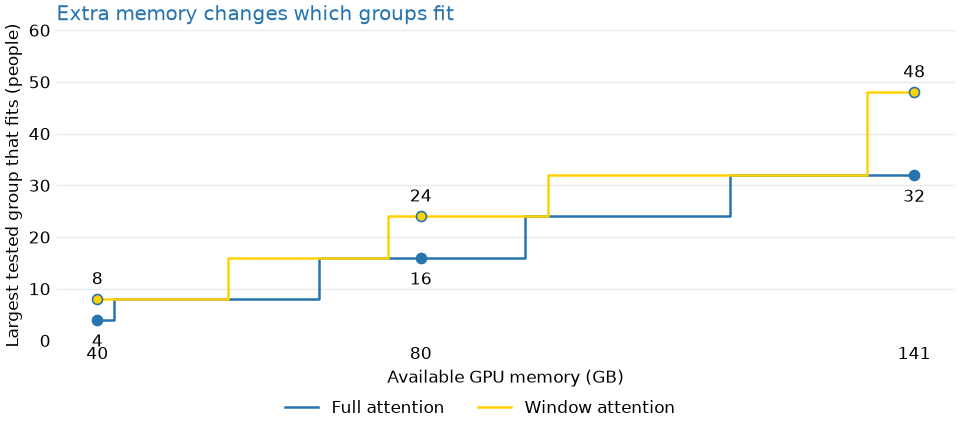

Memory available,Full attention: people,Window: people
40 GB,4,8
80 GB,16,24
141 GB,32,48


In [167]:
capacity_rows={policy:run_rapid_sweep([
    dict(prompt=capacity_prompt_tokens,decode=hardware_decode_tokens,batch=batch,hardware=reference_hardware,
         sample_every=hardware_sample_every,**({} if policy=="Full" else dict(window=hardware_window_tokens,interval=hardware_interval)))
    for batch in capacity_batches
],f"Capacity study · {policy}") for policy in ["Full","Window"]}
capacity_summary=[]
for capacity in capacity_gb:
    row={"capacity_gb":capacity}
    for policy,results in capacity_rows.items():
        fits=[r for r in results if r['peak_gib']*1024**3<=capacity*1_000_000_000]
        row[policy]=max((r['batch_size'] for r in fits),default=0)
    capacity_summary.append(row)
fig=Figure(figsize=(8,3.6),layout="constrained",facecolor="white");ax=fig.subplots()
for policy,color in [("Full",UCLA_BLUE),("Window",UCLA_GOLD)]:
    values=[r[policy] for r in capacity_summary]
    # Each step occurs at a RAPID-predicted peak-memory threshold.
    thresholds=sorted({float(capacity_gb[0]),float(capacity_gb[-1])} | {
        r['peak_gib']*1024**3/1e9 for r in capacity_rows[policy]
        if capacity_gb[0]<r['peak_gib']*1024**3/1e9<capacity_gb[-1]
    })
    feasible_counts=[max((r['batch_size'] for r in capacity_rows[policy]
                         if r['peak_gib']*1024**3/1e9<=limit),default=0) for limit in thresholds]
    ax.step(thresholds,feasible_counts,where="post",color=color,label=policy+" attention")
    ax.scatter(capacity_gb,values,color=color,edgecolor=UCLA_BLUE,zorder=3)
    for x,y in zip(capacity_gb,values):ax.annotate(str(y),(x,y),xytext=(0,9 if policy=="Window" else -16),textcoords="offset points",ha="center")
ax.set_xticks(capacity_gb,[str(c) for c in capacity_gb]);ax.set_xlabel("Available GPU memory (GB)")
ax.set_ylabel("Largest tested group that fits (people)");ax.set_title("Extra memory changes which groups fit",color=UCLA_BLUE,loc="left")
ax.set_ylim(0,max(r[p] for r in capacity_summary for p in ["Full","Window"])*1.25);ax.grid(axis="y",color="#e6ebef");ax.tick_params(length=0)
for spine in ax.spines.values():spine.set_visible(False)
fig.legend(*ax.get_legend_handles_labels(),loc="outside lower center",ncols=2,frameon=False)
output=BytesIO();fig.savefig(output,format="png",dpi=120,facecolor="white");fig.clear();display(Image(data=output.getvalue(),width=1000))
show_table("Memory capacity · same model and 8,192-token prompt",["Memory available","Full attention: people","Window: people"],[
    (f"{r['capacity_gb']} GB",str(r['Full']),str(r['Window'])) for r in capacity_summary
])


### 8.5. What the hardware study tells us


In [169]:
low,high=capacity_summary[0],capacity_summary[-1]
lo=min(gpu_gains);hi=max(gpu_gains)
display(HTML(
    '<div style="max-width:1000px; font-family:system-ui,sans-serif; line-height:1.6; color:#FFFFFF; '
    f'border-left:4px solid {UCLA_GOLD}; padding-left:18px;">'
    '<p><strong>My memory-scaling intuition was right.</strong> At the same model size and token count, the window removes the same number of cache bytes on every GPU.</p>'
    f'<p><strong>Speed is a separate question.</strong> Across the three GPU-like profiles, the same window improved text generation by {lo:.1f}% to {hi:.1f}%. Hardware changes the balance between moving data and doing calculations.</p>'
    f'<p><strong>Fitting in memory creates a threshold.</strong> At {low["capacity_gb"]} GB, the largest tested groups were {low["Full"]} people with full attention and {low["Window"]} with a window; at {high["capacity_gb"]} GB they were {high["Full"]} and {high["Window"]}. A linear reduction in bytes can therefore change which workloads are possible.</p>'
    '</div>'
))
hardware_dir=project_root/"runs/hardware_study";hardware_dir.mkdir(parents=True,exist_ok=True)
_=(hardware_dir/"results.json").write_text(json.dumps(dict(gpu_profiles=gpu_results,bandwidth=bandwidth_results,
    capacity_workloads=capacity_rows,capacity_summary=capacity_summary),indent=2)+"\n")


## 9. References

- [RAPID-LLM paper, Section 4.1](https://arxiv.org/html/2512.19606v1#S4.SS1) — workload, timing, and memory modeling.
- [Original RAPID-LLM repository](https://github.com/nanocad-lab/Rapid-LLM/tree/339ef6ab9fe9b38df3e1d1674ef55121792aa421) — local changes add the single-GPU sliding-window decode and resident-cache model.
- [Transformers cache strategies](https://huggingface.co/docs/transformers/main/kv_cache) — bounded cache growth for sliding-window layers.

- [Mistral 7B paper](https://arxiv.org/html/2310.06825v1) and [official configuration](https://huggingface.co/mistralai/Mistral-7B-v0.1/raw/main/config.json) — sliding-window cache reference.
- [Koyeb published Llama 3.1 8B measurements](https://www.koyeb.com/deploy/llama-3-1-8b-instruct#benchmarks) — actual input/output counts and wall-clock times; snapshot recorded in `data/published_references.json`.
- [NVIDIA A100 specification](https://developer.nvidia.com/blog/supercharging-worlds-fastest-ai-supercomputing-platform-on-hgx-a100-80gb-gpus/) and [H100/H200 specifications](https://docs.nvidia.com/enterprise-reference-architectures/hgx-ai-factory-h100-h200-b200/latest/components.html) — hardware capacity and bandwidth.
